In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


## Step 2: Configuration and Setup

Let's set up our hyperparameters (settings that control how our model learns). These are like the "knobs" we can turn to adjust our model's behavior.


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 28 * 28    # Dimension of noise input to generator
HIDDEN_DIM = 1024      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 2e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 1024
Generator learning rate: 0.0002
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 3,706,640
Discriminator parameters: 2,904,065
Generator learning rate: 0.0002
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=1024, bias=True)
    (3): ReLU()
    (4): Linear(in_features=1024, out_features=1024, bias=True)
    (5): ReLU()
    (6): Linear(in_features=1024, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=1024, out_features=1024, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=1024, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=1, bias=True)
    (7):

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.390689	G_loss: 0.698563
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.132987	G_loss: 1.230506
Epoch: 1 [12800/60000 (21%)]	D_loss: 0.379741	G_loss: 3.526251
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.783173	G_loss: 4.432780
Epoch: 1 [25600/60000 (43%)]	D_loss: 0.838697	G_loss: 3.352769
Epoch: 1 [32000/60000 (53%)]	D_loss: 0.811720	G_loss: 6.302294
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.621298	G_loss: 4.747901
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.468652	G_loss: 4.566953
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.254632	G_loss: 3.881984
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.534773	G_loss: 3.332412
====> Epoch: 1 Train D_loss: 0.8795, Train G_loss: 3.5350
====> Epoch: 1 Val D_loss: 0.7918, Val G_loss: 1.2612
📈 Epoch 1 Summary:
   Train D Loss: 0.8795, Val D Loss: 0.7918
   Train G Loss: 3.5350, Val G Loss: 1.2612

📊 Epoch 2/100
------------------------

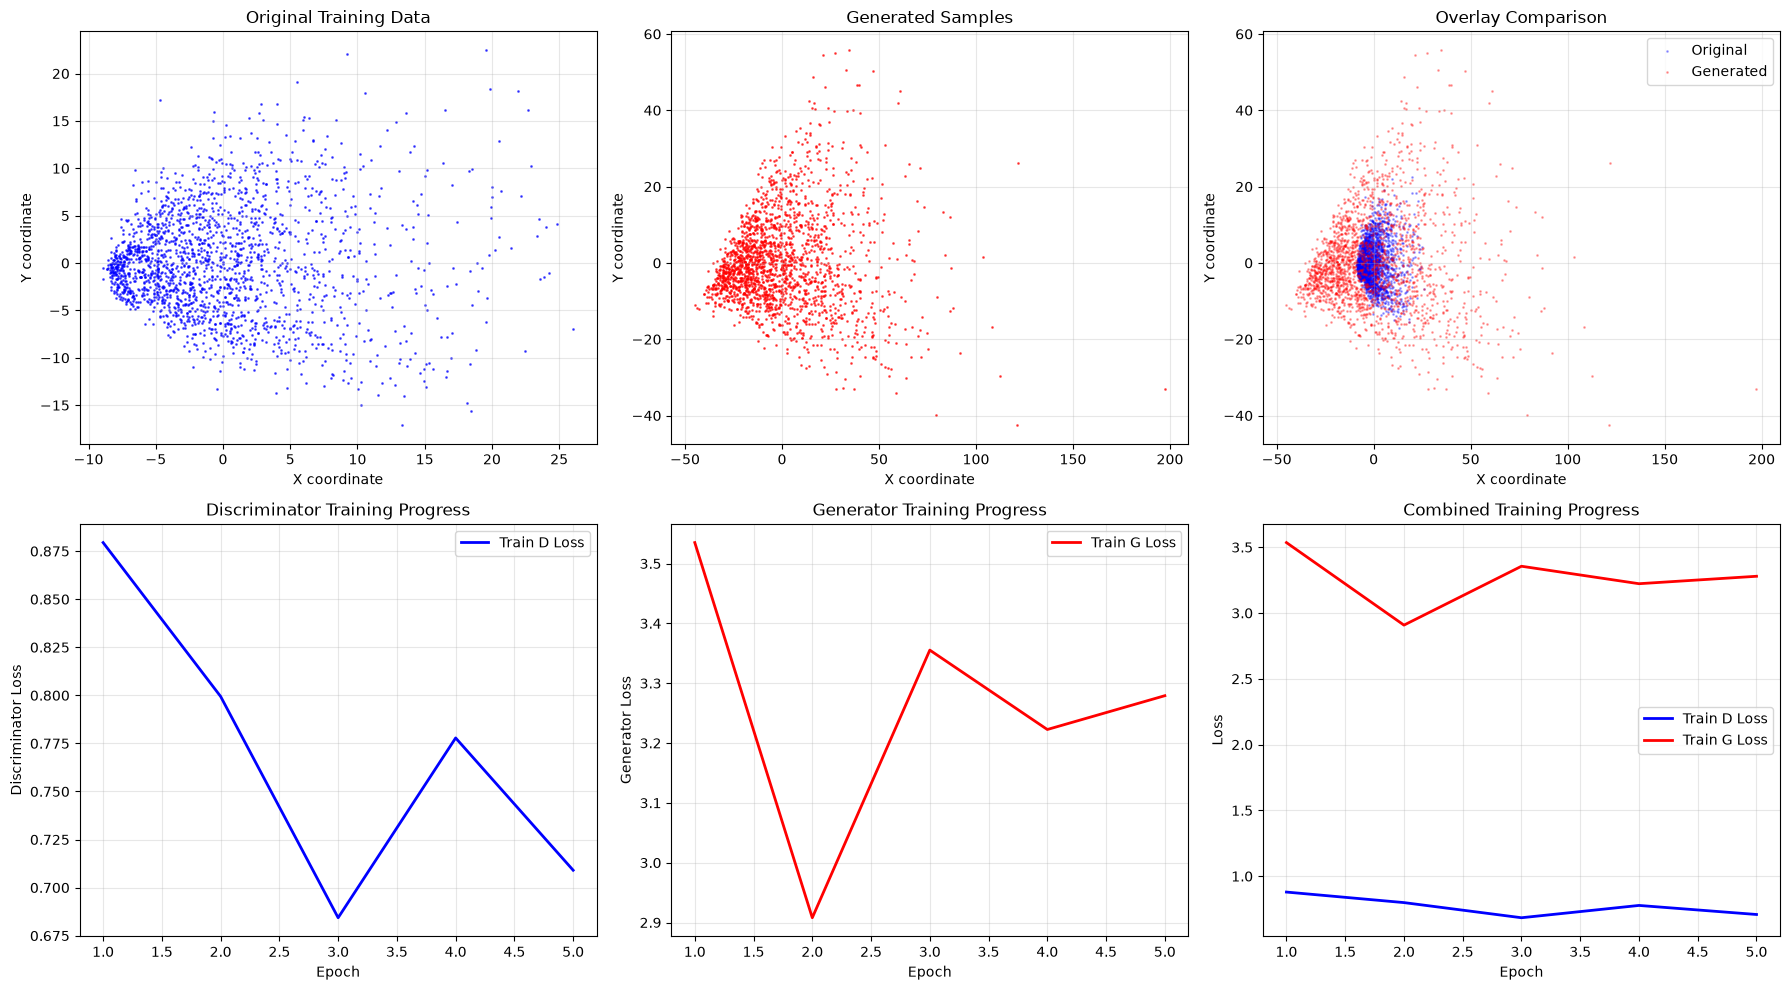

📈 Epoch 5 Summary:
   Train D Loss: 0.7090, Val D Loss: 1.1585
   Train G Loss: 3.2791, Val G Loss: 1.7079

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.940592	G_loss: 4.142900
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.225068	G_loss: 4.817688
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.502640	G_loss: 4.276379
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.351664	G_loss: 3.583395
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.639944	G_loss: 4.601231
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.513485	G_loss: 2.806545
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.901648	G_loss: 3.077794
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.575700	G_loss: 4.585014
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.431398	G_loss: 2.822099
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.904306	G_loss: 1.705524
====> Epoch: 6 Train D_loss: 0.6539, Train G_loss: 3.6751
====> Epoch: 6 Val D_loss: 0.4101, Val G_loss: 1.6817
📈 Epoch 6 Summary:
   Train D Loss: 0.6539, Val D Loss: 0.4101
   Train G Loss: 3.6751, Val G Loss: 1

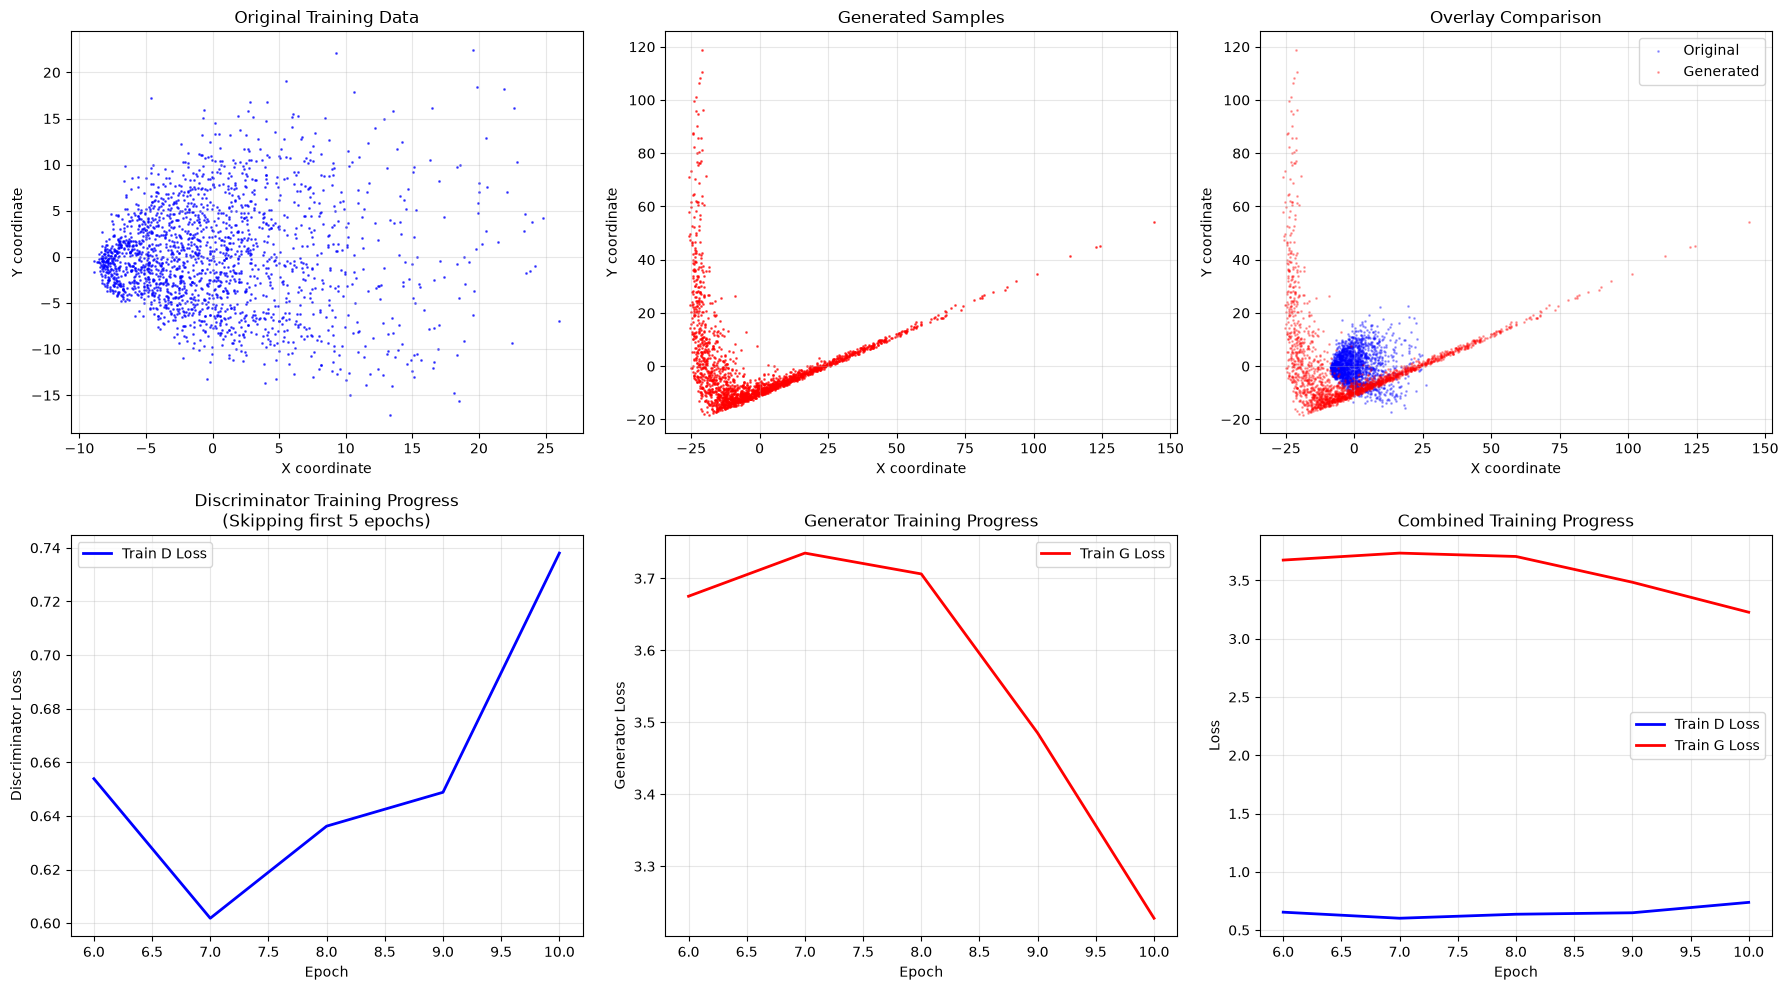

📈 Epoch 10 Summary:
   Train D Loss: 0.7380, Val D Loss: 0.5898
   Train G Loss: 3.2277, Val G Loss: 1.9694

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.604729	G_loss: 3.348450
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.829942	G_loss: 2.860856
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.567052	G_loss: 3.441575
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.859992	G_loss: 2.832527
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.782571	G_loss: 2.891429
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.767058	G_loss: 2.199631
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.833525	G_loss: 3.070737
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.555017	G_loss: 2.661405
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.984376	G_loss: 2.660158
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.694895	G_loss: 4.139663
====> Epoch: 11 Train D_loss: 0.7861, Train G_loss: 3.1273
====> Epoch: 11 Val D_loss: 0.6811, Val G_loss: 1.4787
📈 Epoch 11 Summary:
   Train D Loss: 0.7861, Val D Loss: 0.6811
   Train G Loss: 3.1273

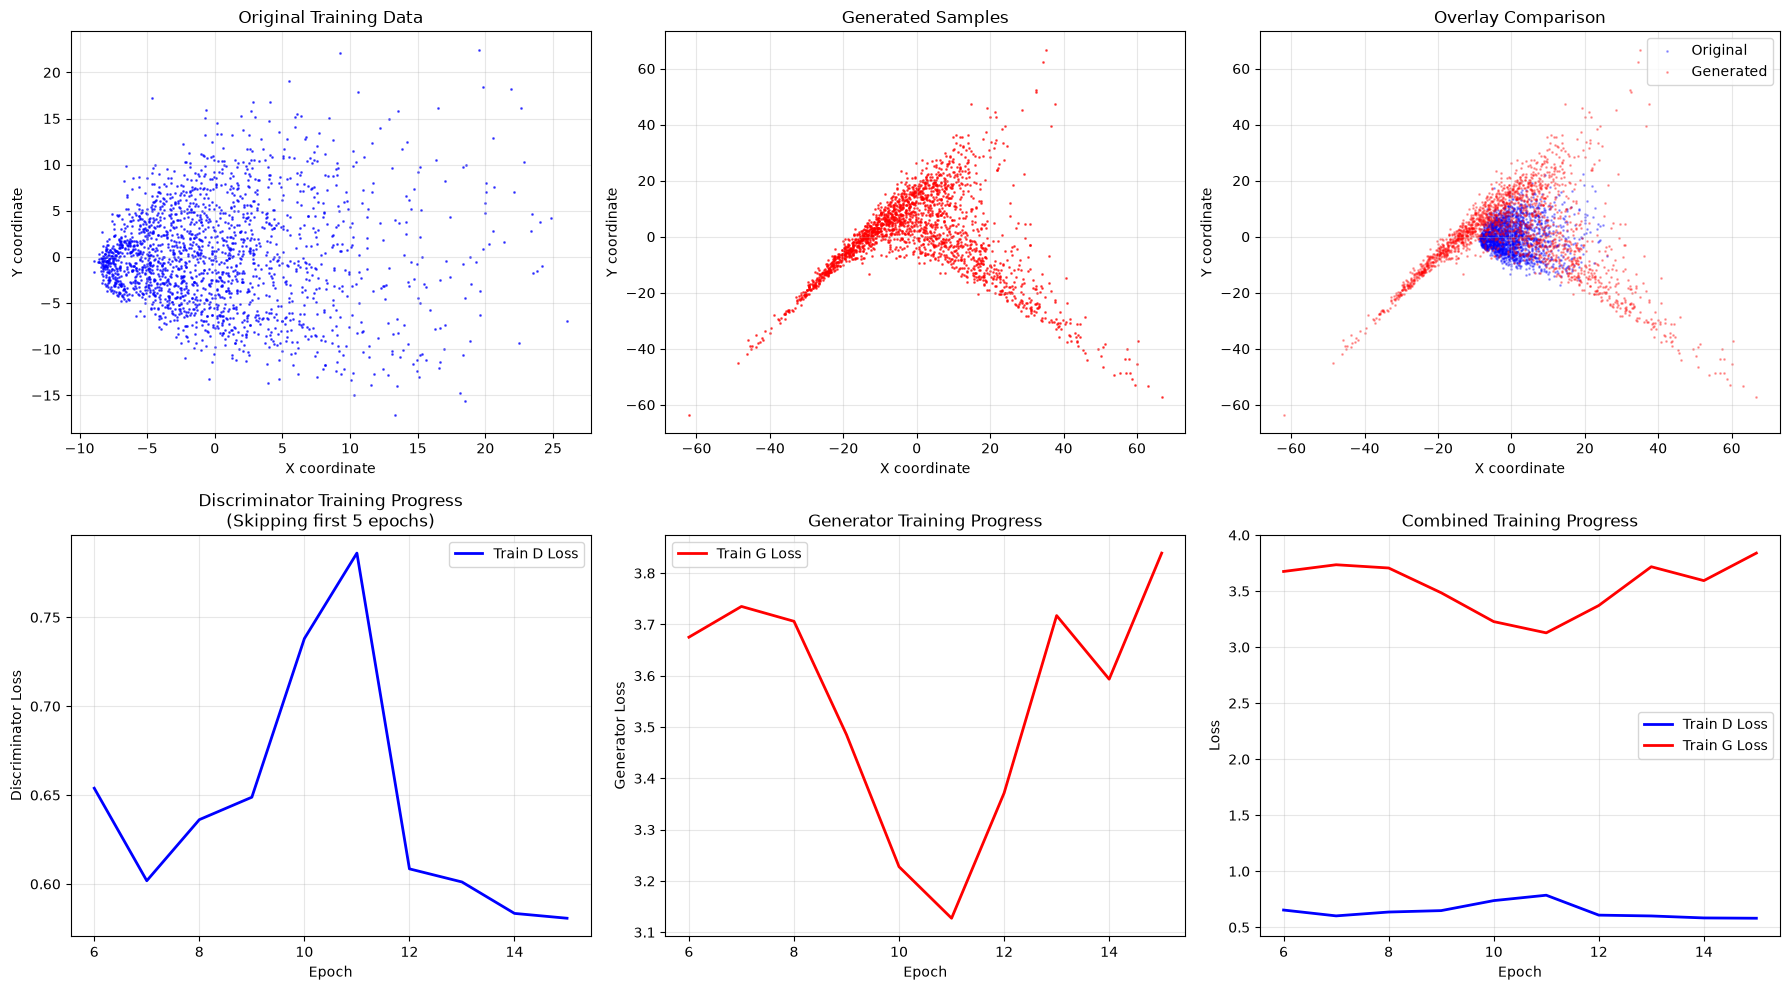

📈 Epoch 15 Summary:
   Train D Loss: 0.5807, Val D Loss: 0.6457
   Train G Loss: 3.8391, Val G Loss: 2.0950

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.557407	G_loss: 3.373074
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.418274	G_loss: 3.225060
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.459812	G_loss: 3.715455
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.441920	G_loss: 3.601060
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.439473	G_loss: 3.521216
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.590675	G_loss: 4.031304
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.388594	G_loss: 4.650491
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.447832	G_loss: 3.355428
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.756942	G_loss: 4.032583
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.760853	G_loss: 2.746473
====> Epoch: 16 Train D_loss: 0.5613, Train G_loss: 3.9488
====> Epoch: 16 Val D_loss: 0.6149, Val G_loss: 1.6110
📈 Epoch 16 Summary:
   Train D Loss: 0.5613, Val D Loss: 0.6149
   Train G Loss: 3.9488

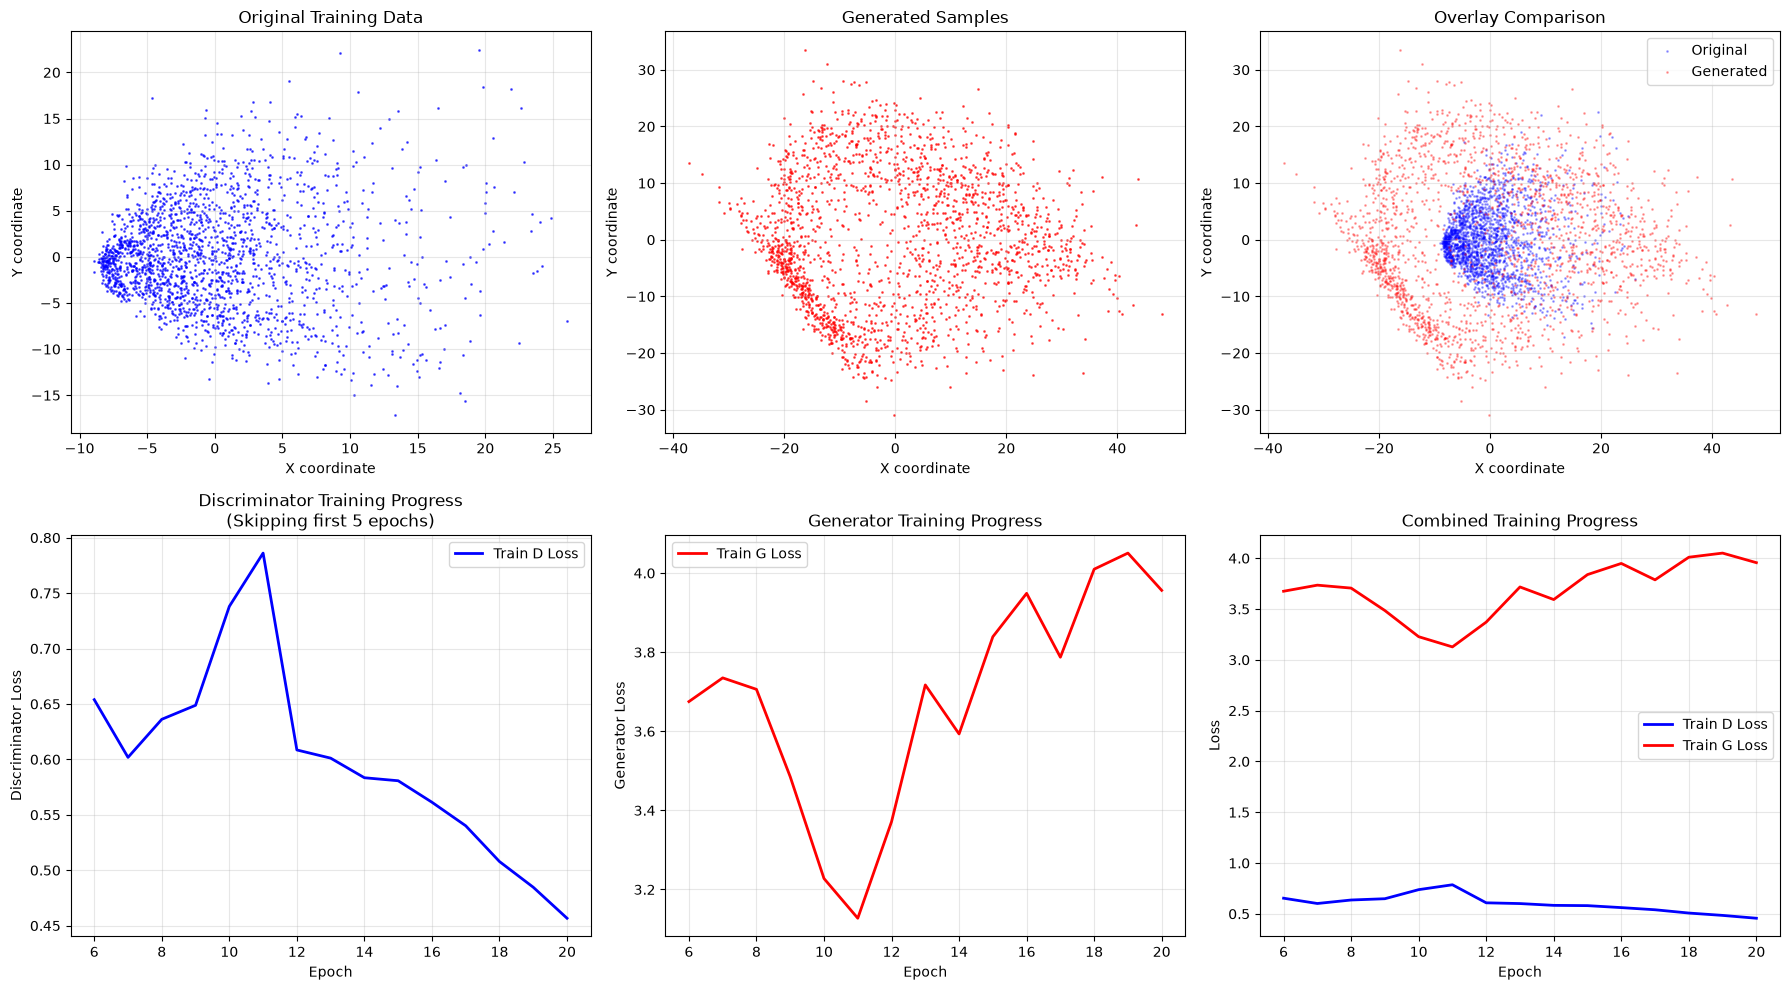

📈 Epoch 20 Summary:
   Train D Loss: 0.4567, Val D Loss: 0.4897
   Train G Loss: 3.9564, Val G Loss: 2.0622

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.497795	G_loss: 3.893842
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.338061	G_loss: 4.121207
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.457971	G_loss: 4.299006
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.355427	G_loss: 3.397507
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.469346	G_loss: 3.760337
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.505730	G_loss: 4.730914
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.536157	G_loss: 5.142964
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.446160	G_loss: 3.422446
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.393130	G_loss: 3.730733
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.464814	G_loss: 5.029531
====> Epoch: 21 Train D_loss: 0.4727, Train G_loss: 3.9871
====> Epoch: 21 Val D_loss: 0.3748, Val G_loss: 2.3474
📈 Epoch 21 Summary:
   Train D Loss: 0.4727, Val D Loss: 0.3748
   Train G Loss: 3.9871

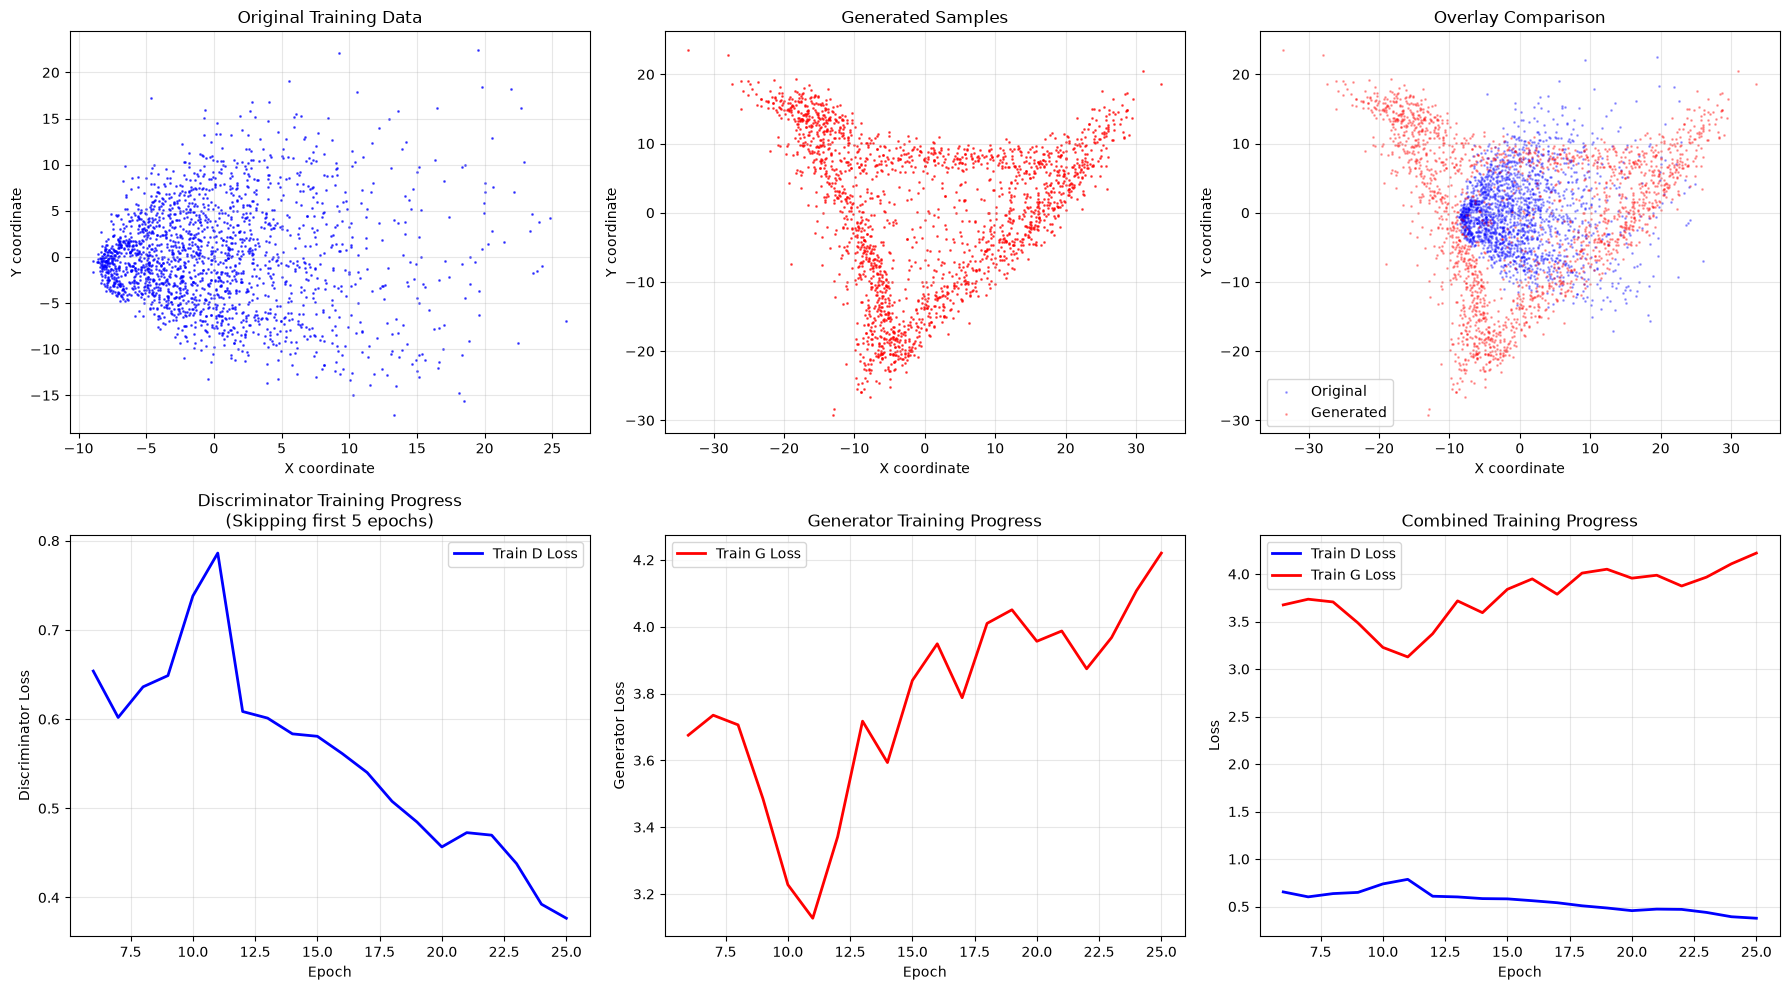

📈 Epoch 25 Summary:
   Train D Loss: 0.3767, Val D Loss: 0.4173
   Train G Loss: 4.2203, Val G Loss: 3.0089

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.346459	G_loss: 4.272370
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.262965	G_loss: 4.642738
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.478446	G_loss: 4.498176
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.245195	G_loss: 3.750267
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.406601	G_loss: 4.093922
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.227777	G_loss: 4.025727
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.339376	G_loss: 3.594630
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.286744	G_loss: 4.449574
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.202184	G_loss: 3.564044
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.292705	G_loss: 3.952845
====> Epoch: 26 Train D_loss: 0.3380, Train G_loss: 4.4515
====> Epoch: 26 Val D_loss: 0.2874, Val G_loss: 3.1435
📈 Epoch 26 Summary:
   Train D Loss: 0.3380, Val D Loss: 0.2874
   Train G Loss: 4.4515

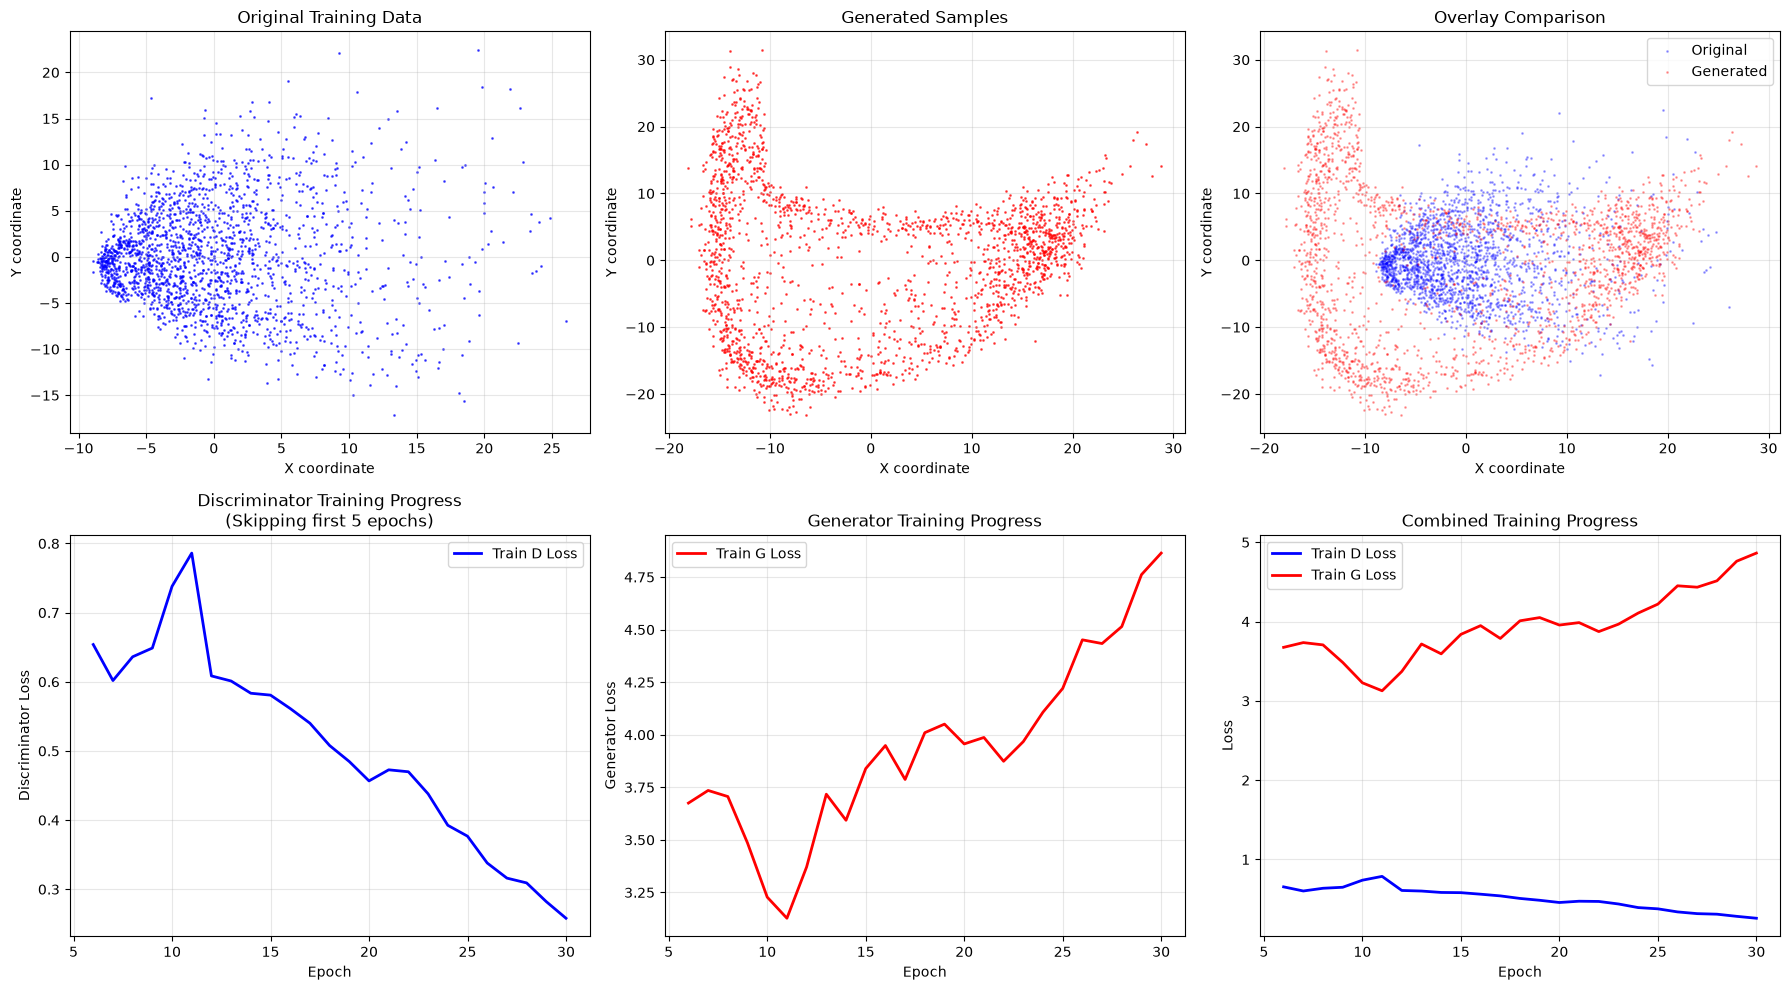

📈 Epoch 30 Summary:
   Train D Loss: 0.2581, Val D Loss: 0.2634
   Train G Loss: 4.8641, Val G Loss: 3.5423

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.262565	G_loss: 3.452270
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.166703	G_loss: 4.246307
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.163863	G_loss: 5.477608
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.179496	G_loss: 4.862939
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.240702	G_loss: 4.917061
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.138214	G_loss: 5.075663
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.160902	G_loss: 4.255813
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.191179	G_loss: 4.928891
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.170269	G_loss: 4.690702
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.132458	G_loss: 4.672883
====> Epoch: 31 Train D_loss: 0.2446, Train G_loss: 4.9681
====> Epoch: 31 Val D_loss: 0.2945, Val G_loss: 4.5607
📈 Epoch 31 Summary:
   Train D Loss: 0.2446, Val D Loss: 0.2945
   Train G Loss: 4.9681

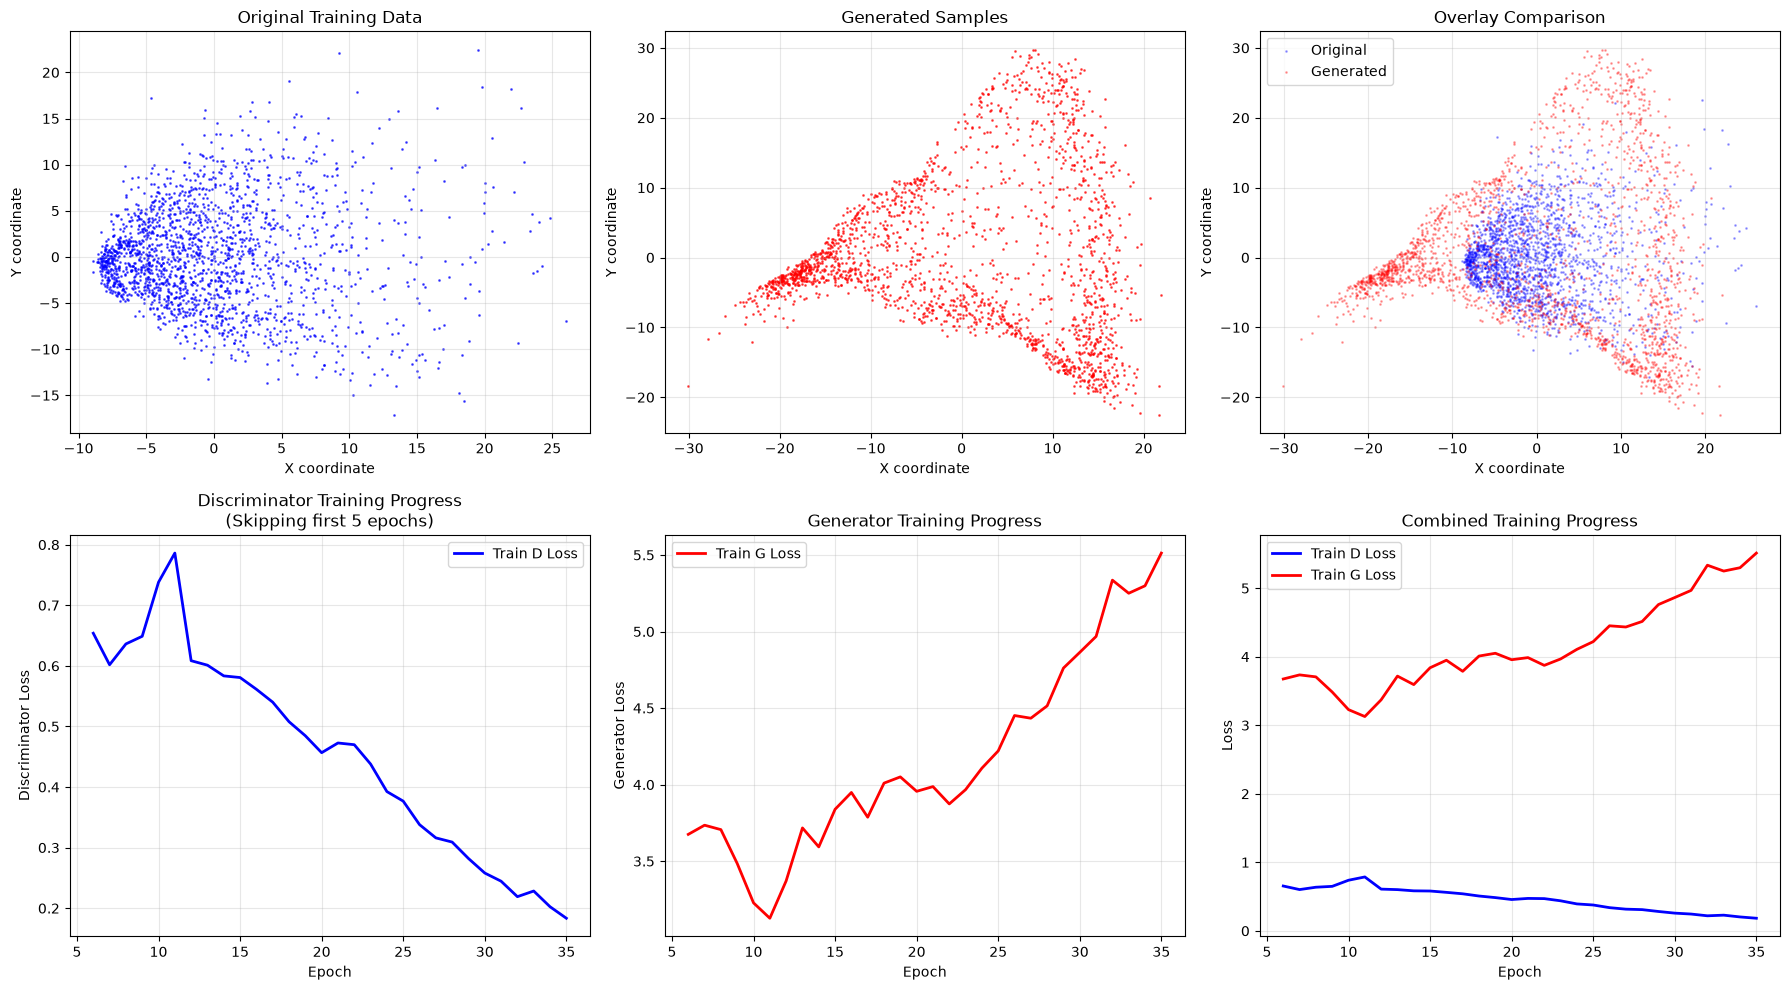

📈 Epoch 35 Summary:
   Train D Loss: 0.1835, Val D Loss: 0.5756
   Train G Loss: 5.5125, Val G Loss: 8.9261

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.695575	G_loss: 5.705454
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.104716	G_loss: 5.698838
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.415161	G_loss: 8.503152
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.130781	G_loss: 4.561990
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.234297	G_loss: 8.992959
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.120798	G_loss: 5.286950
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.150728	G_loss: 4.056219
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.111531	G_loss: 5.519450
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.128550	G_loss: 4.625925
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.309328	G_loss: 7.691498
====> Epoch: 36 Train D_loss: 0.1864, Train G_loss: 5.5331
====> Epoch: 36 Val D_loss: 0.3203, Val G_loss: 6.3247
📈 Epoch 36 Summary:
   Train D Loss: 0.1864, Val D Loss: 0.3203
   Train G Loss: 5.5331

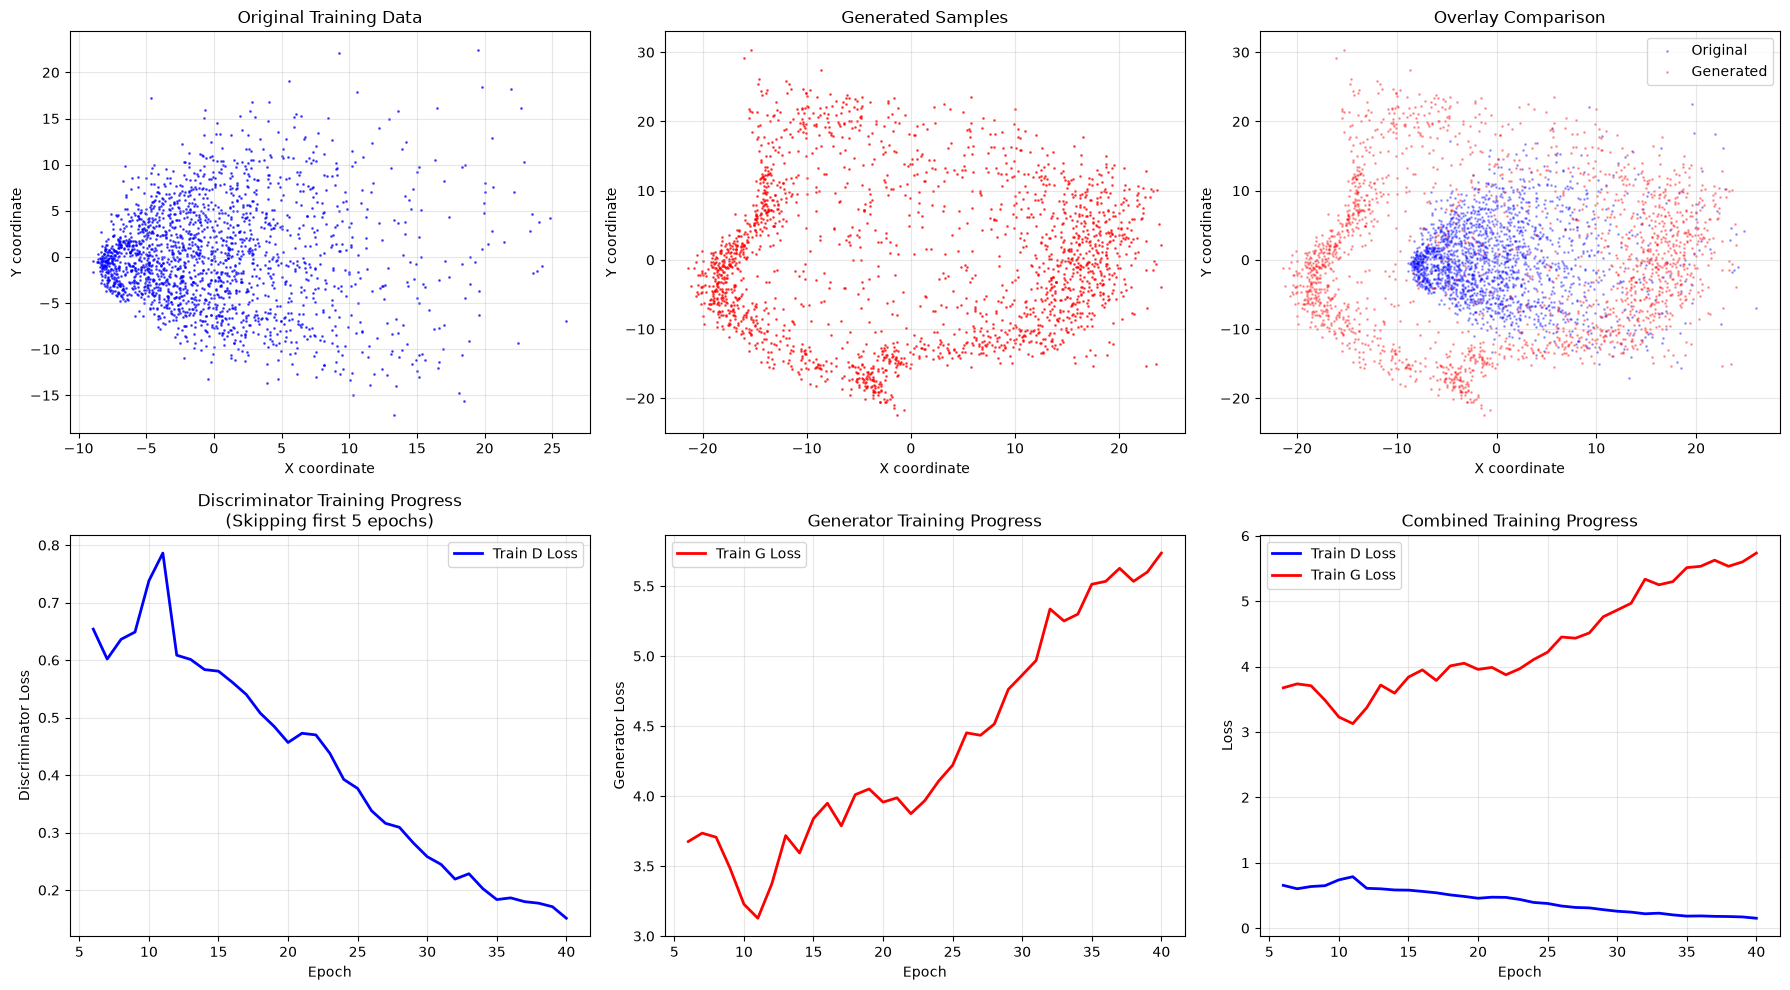

📈 Epoch 40 Summary:
   Train D Loss: 0.1510, Val D Loss: 0.1497
   Train G Loss: 5.7350, Val G Loss: 4.8124

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.187307	G_loss: 5.589324
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.075107	G_loss: 4.944630
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.136283	G_loss: 5.376809
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.090782	G_loss: 5.173503
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.138042	G_loss: 6.339211
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.057556	G_loss: 6.348085
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.139809	G_loss: 4.566666
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.144921	G_loss: 4.905675
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.126817	G_loss: 4.726940
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.084255	G_loss: 4.479931
====> Epoch: 41 Train D_loss: 0.1692, Train G_loss: 5.5873
====> Epoch: 41 Val D_loss: 0.0900, Val G_loss: 4.8708
📈 Epoch 41 Summary:
   Train D Loss: 0.1692, Val D Loss: 0.0900
   Train G Loss: 5.5873

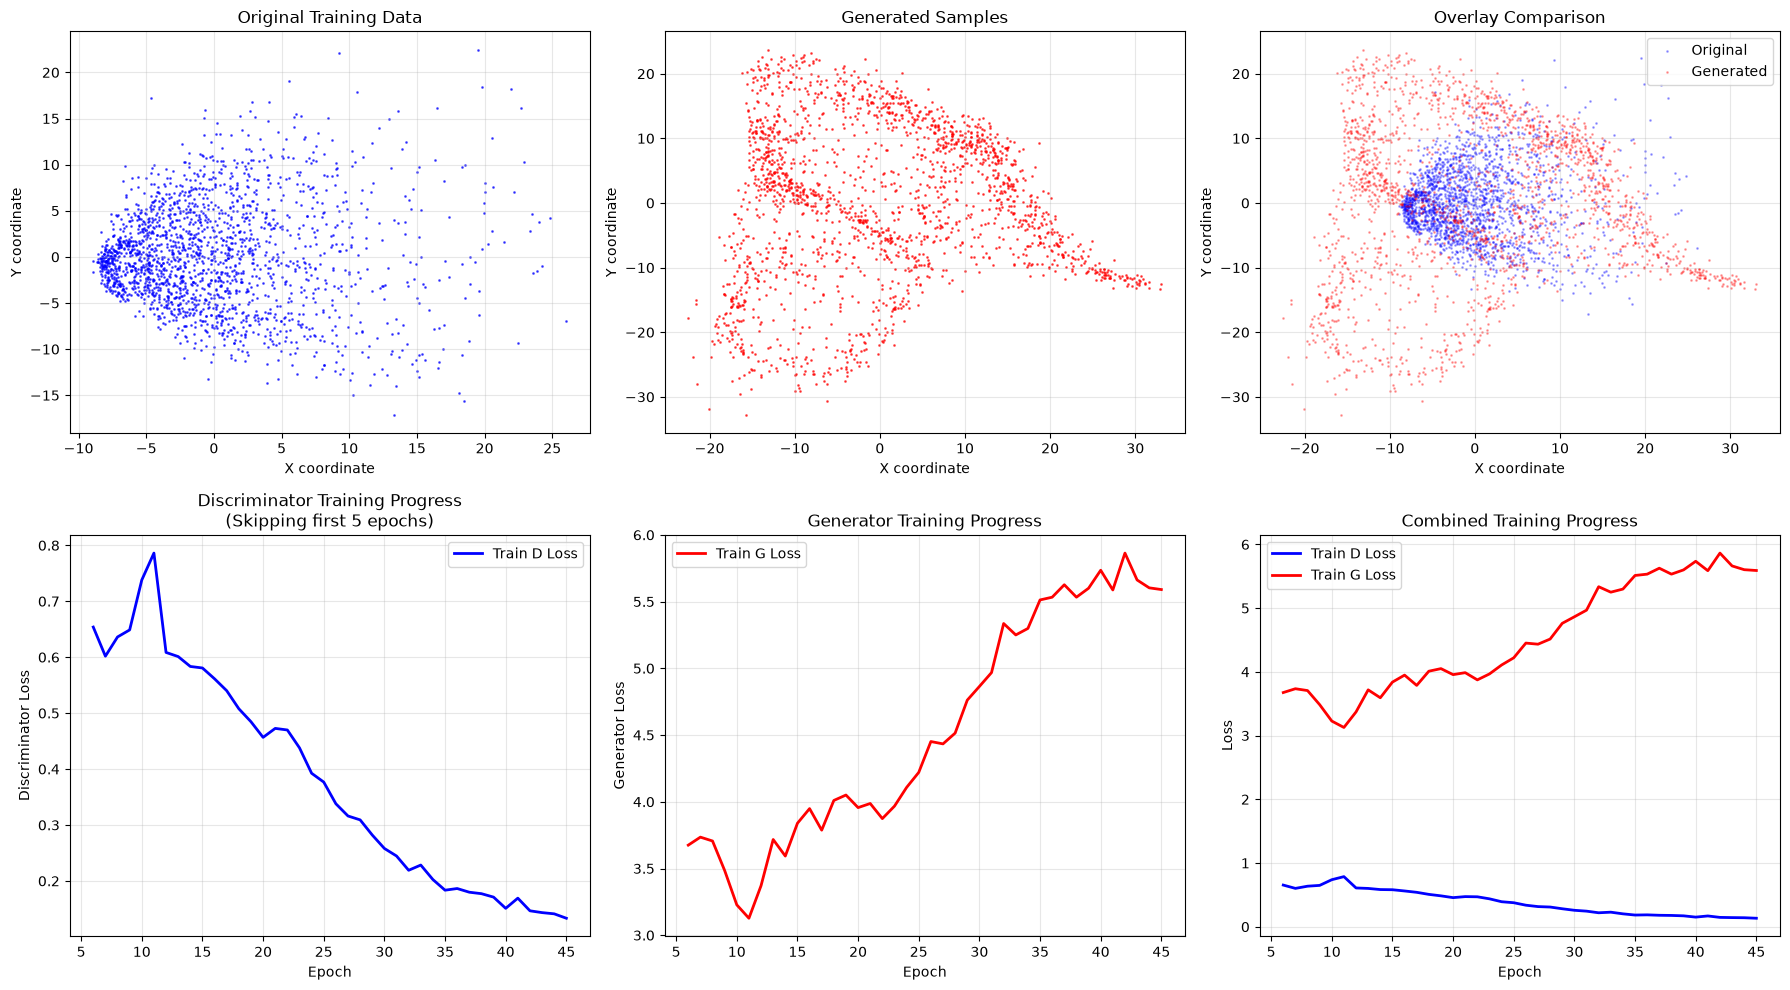

📈 Epoch 45 Summary:
   Train D Loss: 0.1333, Val D Loss: 0.1053
   Train G Loss: 5.5904, Val G Loss: 4.9034

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.213435	G_loss: 4.247213
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.192804	G_loss: 4.620513
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.091100	G_loss: 5.829384
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.137910	G_loss: 5.140235
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.079490	G_loss: 4.689373
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.208274	G_loss: 4.586358
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.069775	G_loss: 5.132542
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.447295	G_loss: 5.933237
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.095990	G_loss: 5.797072
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.147605	G_loss: 4.211338
====> Epoch: 46 Train D_loss: 0.1281, Train G_loss: 5.5216
====> Epoch: 46 Val D_loss: 0.0839, Val G_loss: 4.3027
📈 Epoch 46 Summary:
   Train D Loss: 0.1281, Val D Loss: 0.0839
   Train G Loss: 5.5216

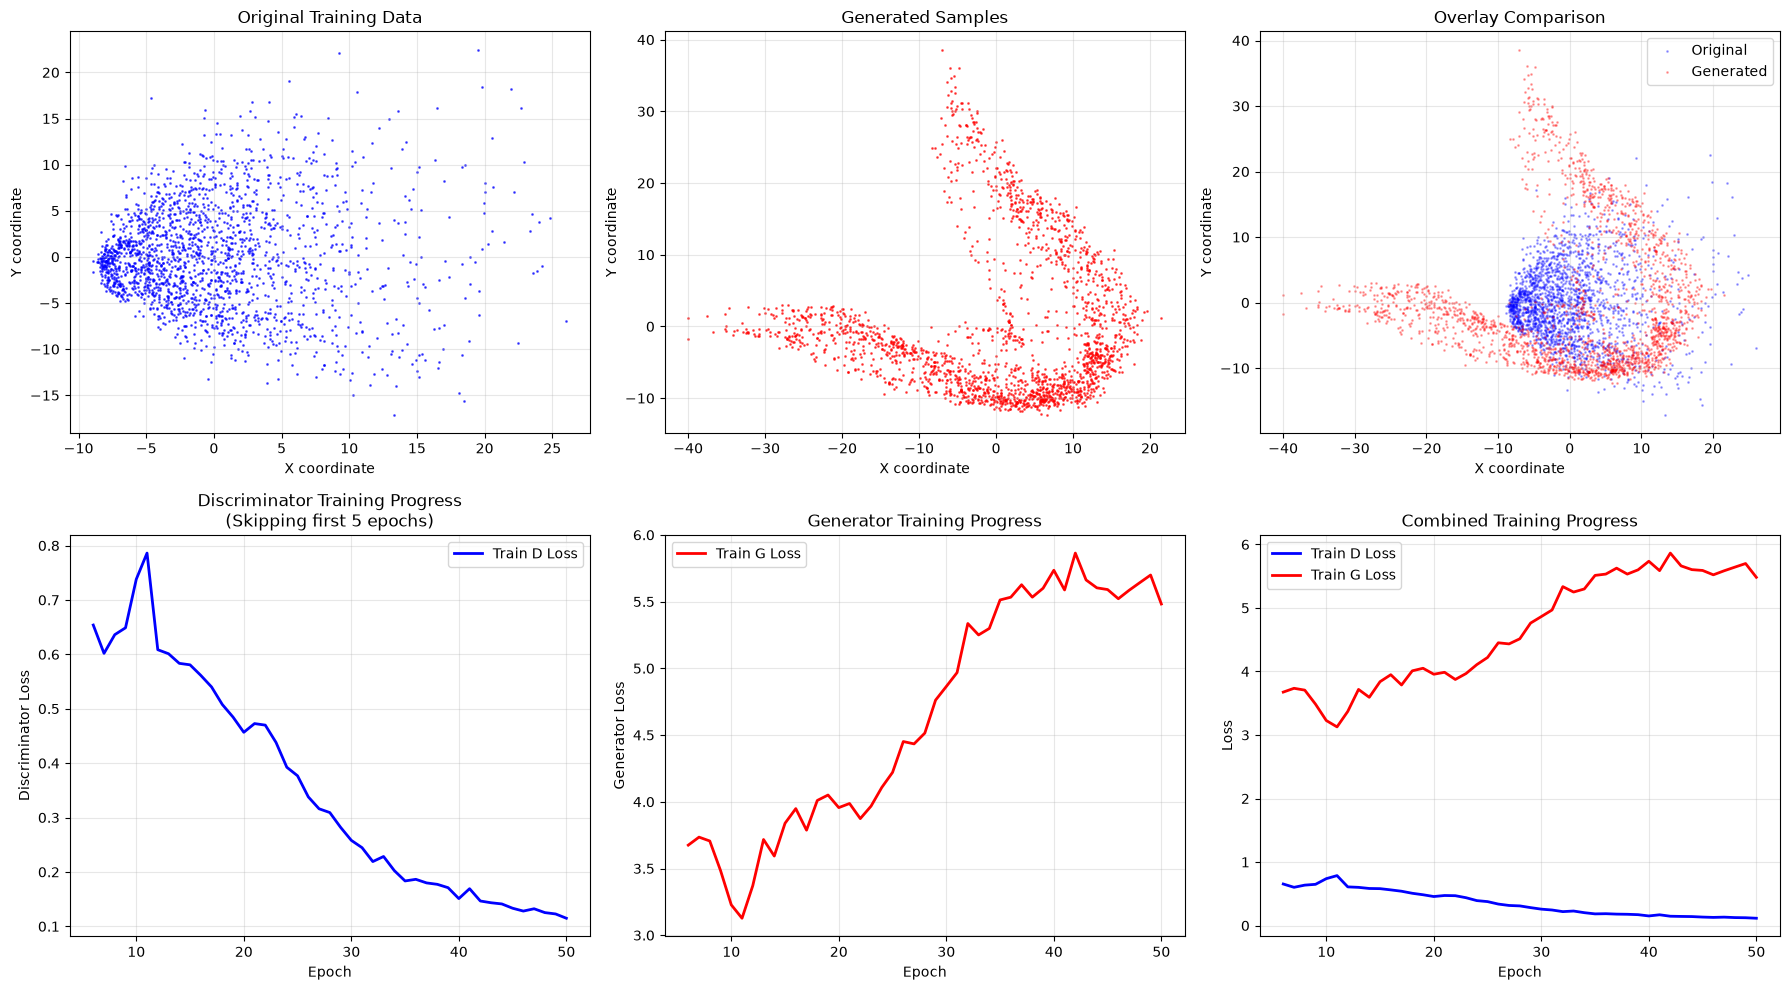

📈 Epoch 50 Summary:
   Train D Loss: 0.1149, Val D Loss: 0.1085
   Train G Loss: 5.4820, Val G Loss: 5.0883

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.105676	G_loss: 5.181542
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.275195	G_loss: 4.246135
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.054020	G_loss: 6.729247
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.031234	G_loss: 6.449736
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.157600	G_loss: 3.592308
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.073230	G_loss: 5.351892
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.197686	G_loss: 6.082332
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.115399	G_loss: 5.188467
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.225181	G_loss: 8.388730
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.079077	G_loss: 4.952096
====> Epoch: 51 Train D_loss: 0.1223, Train G_loss: 5.6610
====> Epoch: 51 Val D_loss: 0.1631, Val G_loss: 6.0873
📈 Epoch 51 Summary:
   Train D Loss: 0.1223, Val D Loss: 0.1631
   Train G Loss: 5.6610

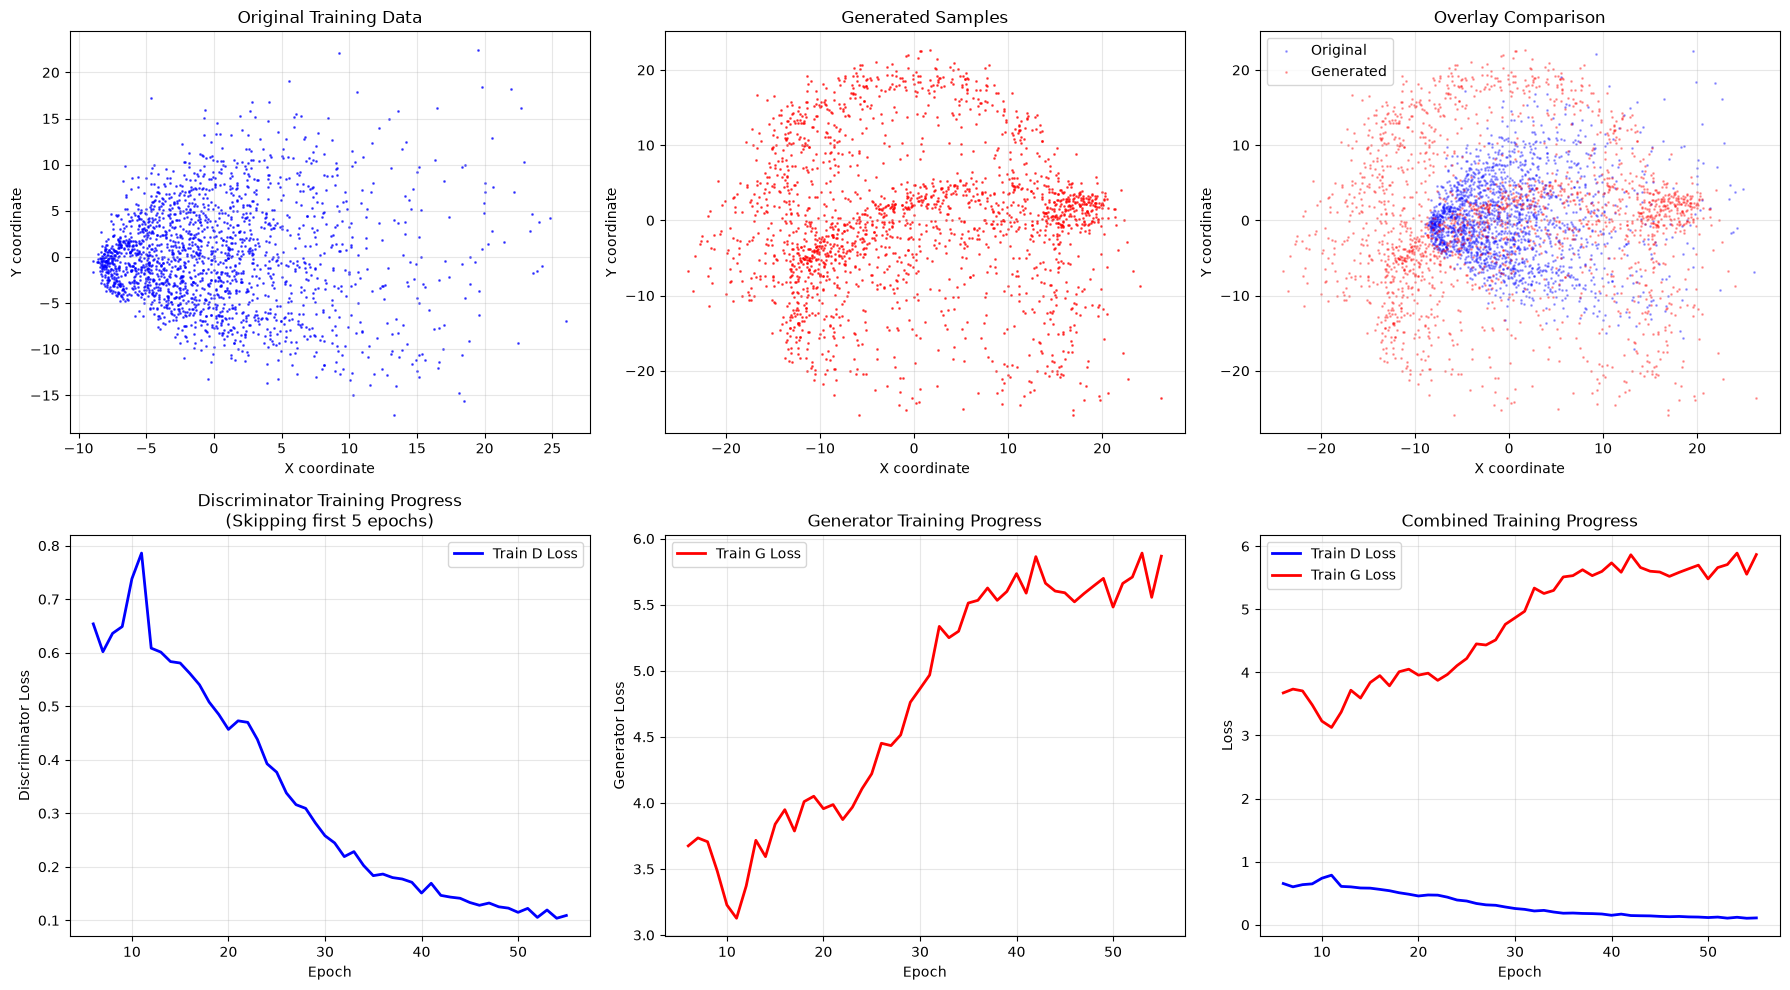

📈 Epoch 55 Summary:
   Train D Loss: 0.1091, Val D Loss: 0.1515
   Train G Loss: 5.8671, Val G Loss: 4.9026

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.172022	G_loss: 5.031377
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.303487	G_loss: 8.020996
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.082653	G_loss: 5.143920
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.138837	G_loss: 4.679255
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.185842	G_loss: 5.839761
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.112066	G_loss: 4.349403
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.099949	G_loss: 7.626262
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.042320	G_loss: 5.123265
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.077176	G_loss: 5.004366
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.124722	G_loss: 6.841942
====> Epoch: 56 Train D_loss: 0.1040, Train G_loss: 5.6491
====> Epoch: 56 Val D_loss: 0.0984, Val G_loss: 3.9425
📈 Epoch 56 Summary:
   Train D Loss: 0.1040, Val D Loss: 0.0984
   Train G Loss: 5.6491

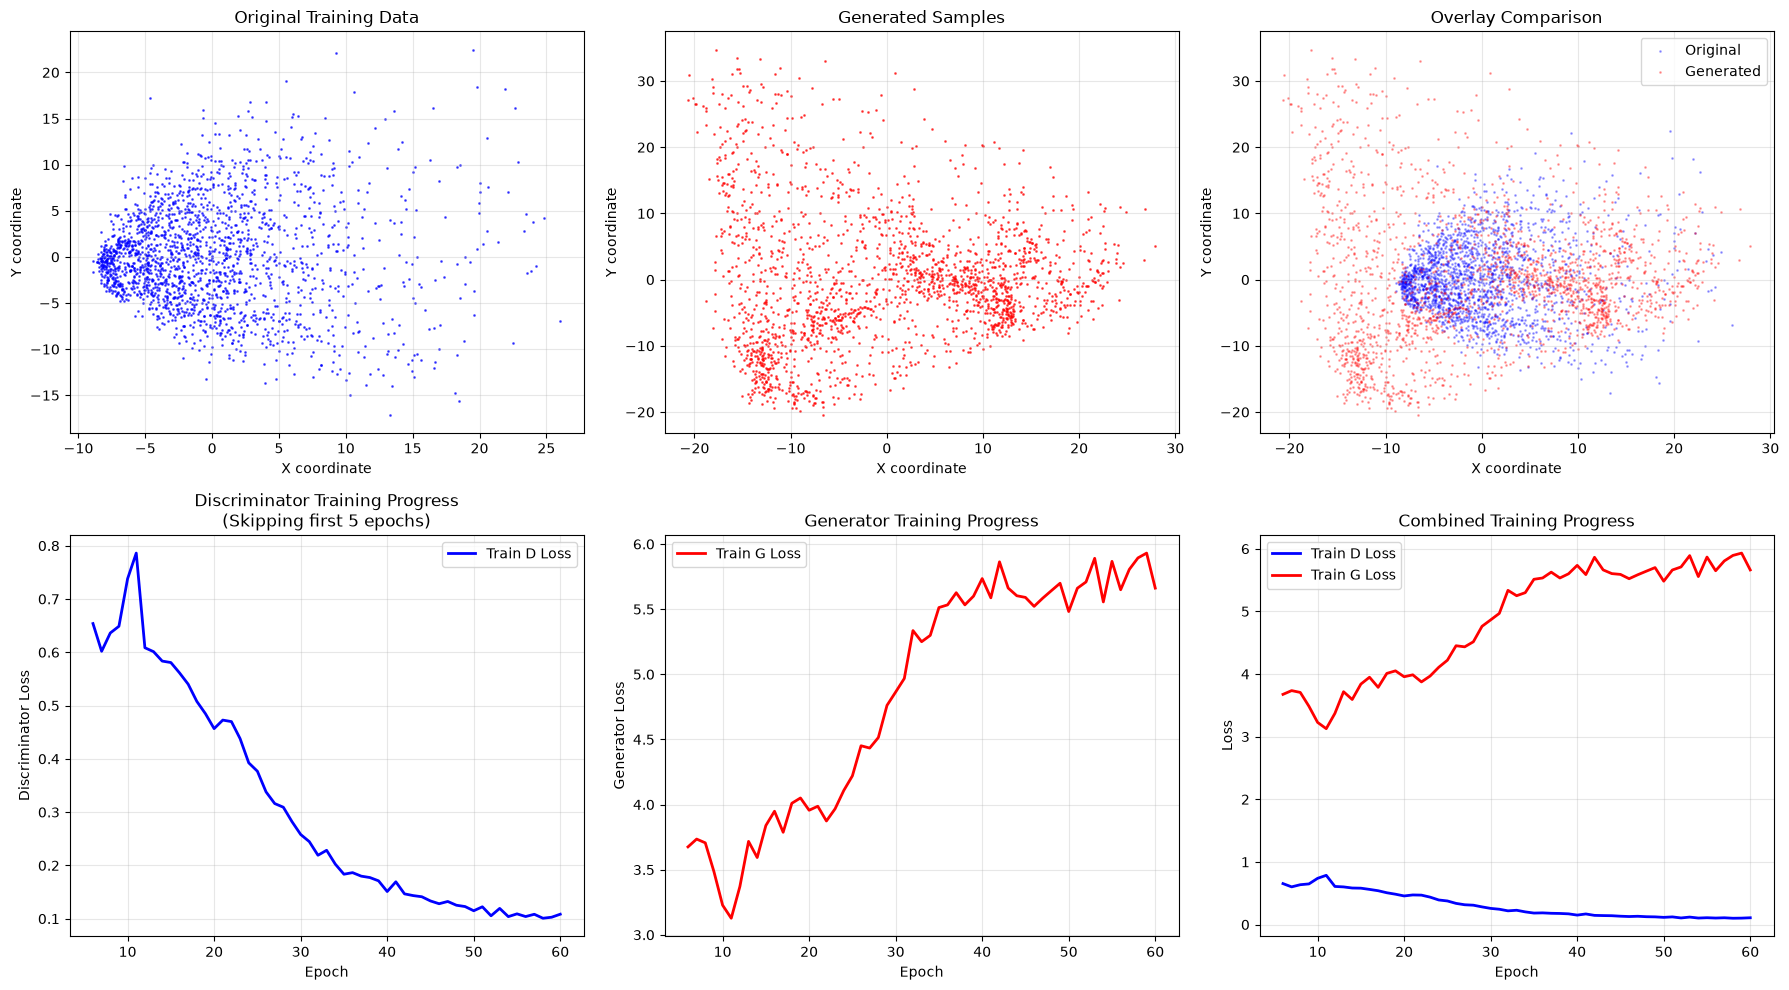

📈 Epoch 60 Summary:
   Train D Loss: 0.1084, Val D Loss: 0.1168
   Train G Loss: 5.6617, Val G Loss: 4.3113

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.116442	G_loss: 5.258524
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.085866	G_loss: 4.514371
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.148676	G_loss: 6.575507
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.033166	G_loss: 5.813074
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.165596	G_loss: 4.762351
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.052519	G_loss: 5.132209
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.054845	G_loss: 5.624596
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.042028	G_loss: 6.050163
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.173164	G_loss: 5.177942
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.186546	G_loss: 6.967128
====> Epoch: 61 Train D_loss: 0.1120, Train G_loss: 5.5173
====> Epoch: 61 Val D_loss: 0.1456, Val G_loss: 5.9063
📈 Epoch 61 Summary:
   Train D Loss: 0.1120, Val D Loss: 0.1456
   Train G Loss: 5.5173

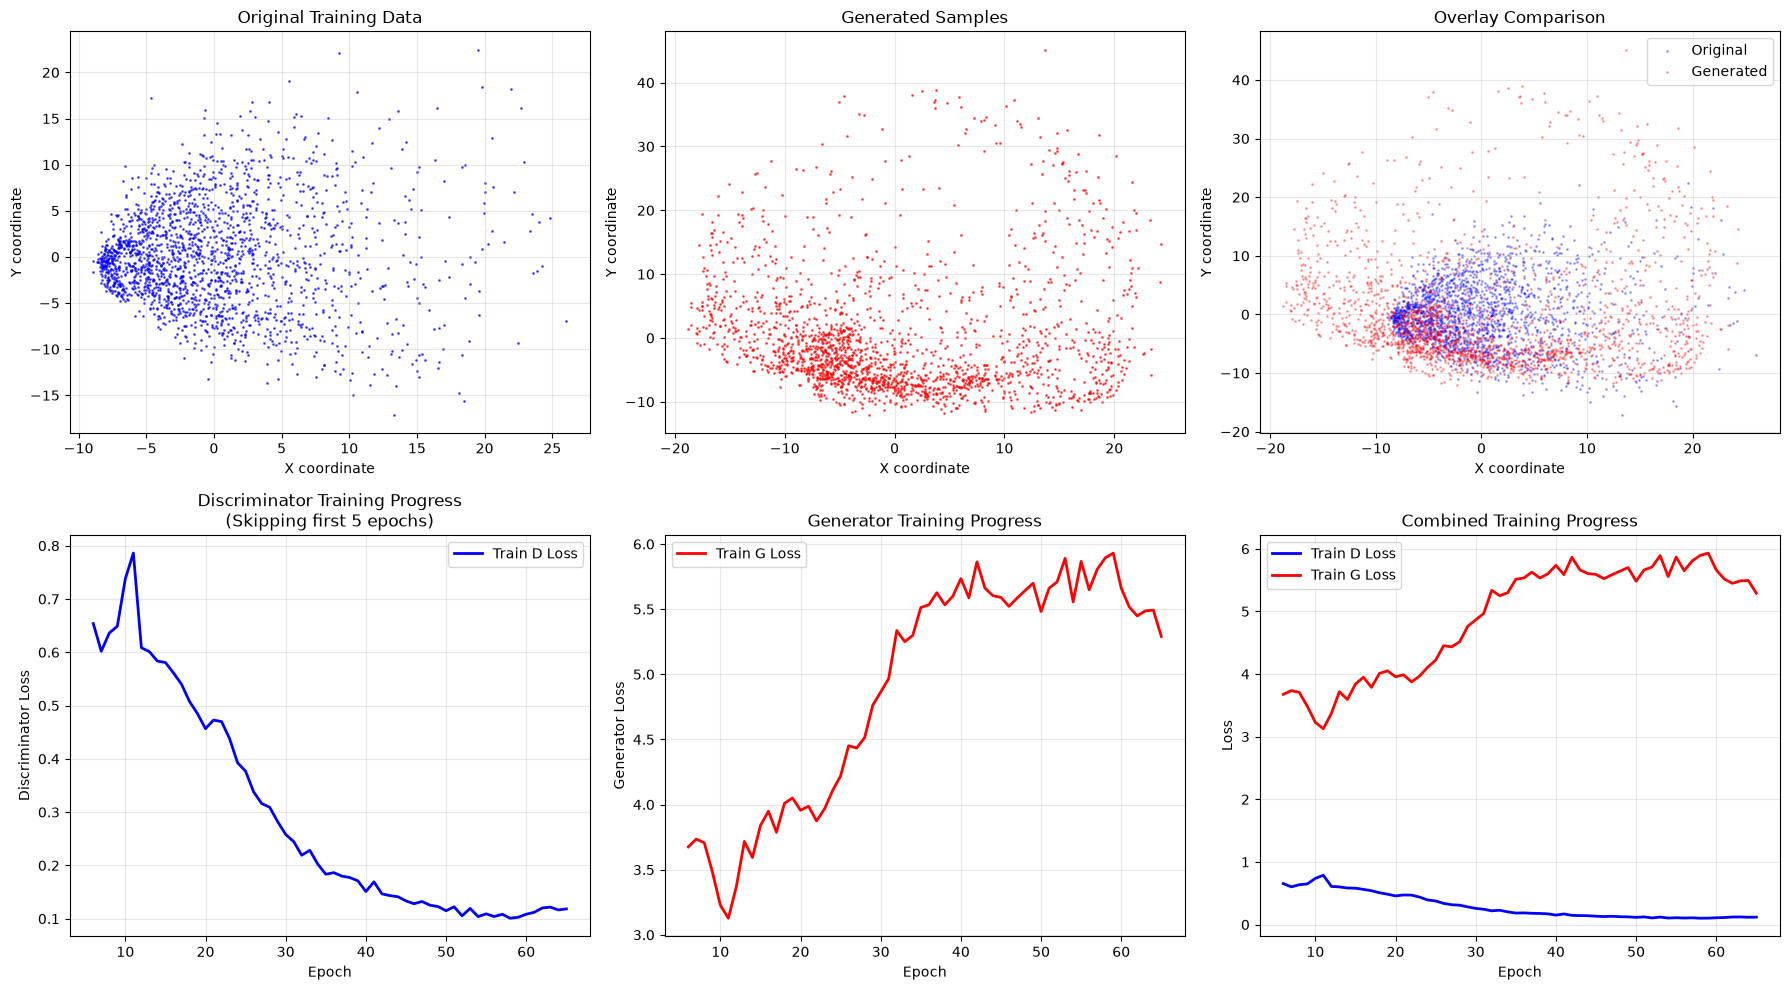

📈 Epoch 65 Summary:
   Train D Loss: 0.1184, Val D Loss: 0.1149
   Train G Loss: 5.2908, Val G Loss: 4.8628

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.145281	G_loss: 3.871454
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.103739	G_loss: 4.930091
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.176206	G_loss: 4.971226
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.267899	G_loss: 3.659265
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.064859	G_loss: 5.806470
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.075825	G_loss: 5.740361
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.101654	G_loss: 5.137468
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.155194	G_loss: 3.255865
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.180288	G_loss: 6.416363
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.091276	G_loss: 5.456406
====> Epoch: 66 Train D_loss: 0.1166, Train G_loss: 5.2926
====> Epoch: 66 Val D_loss: 0.1457, Val G_loss: 5.9364
📈 Epoch 66 Summary:
   Train D Loss: 0.1166, Val D Loss: 0.1457
   Train G Loss: 5.2926

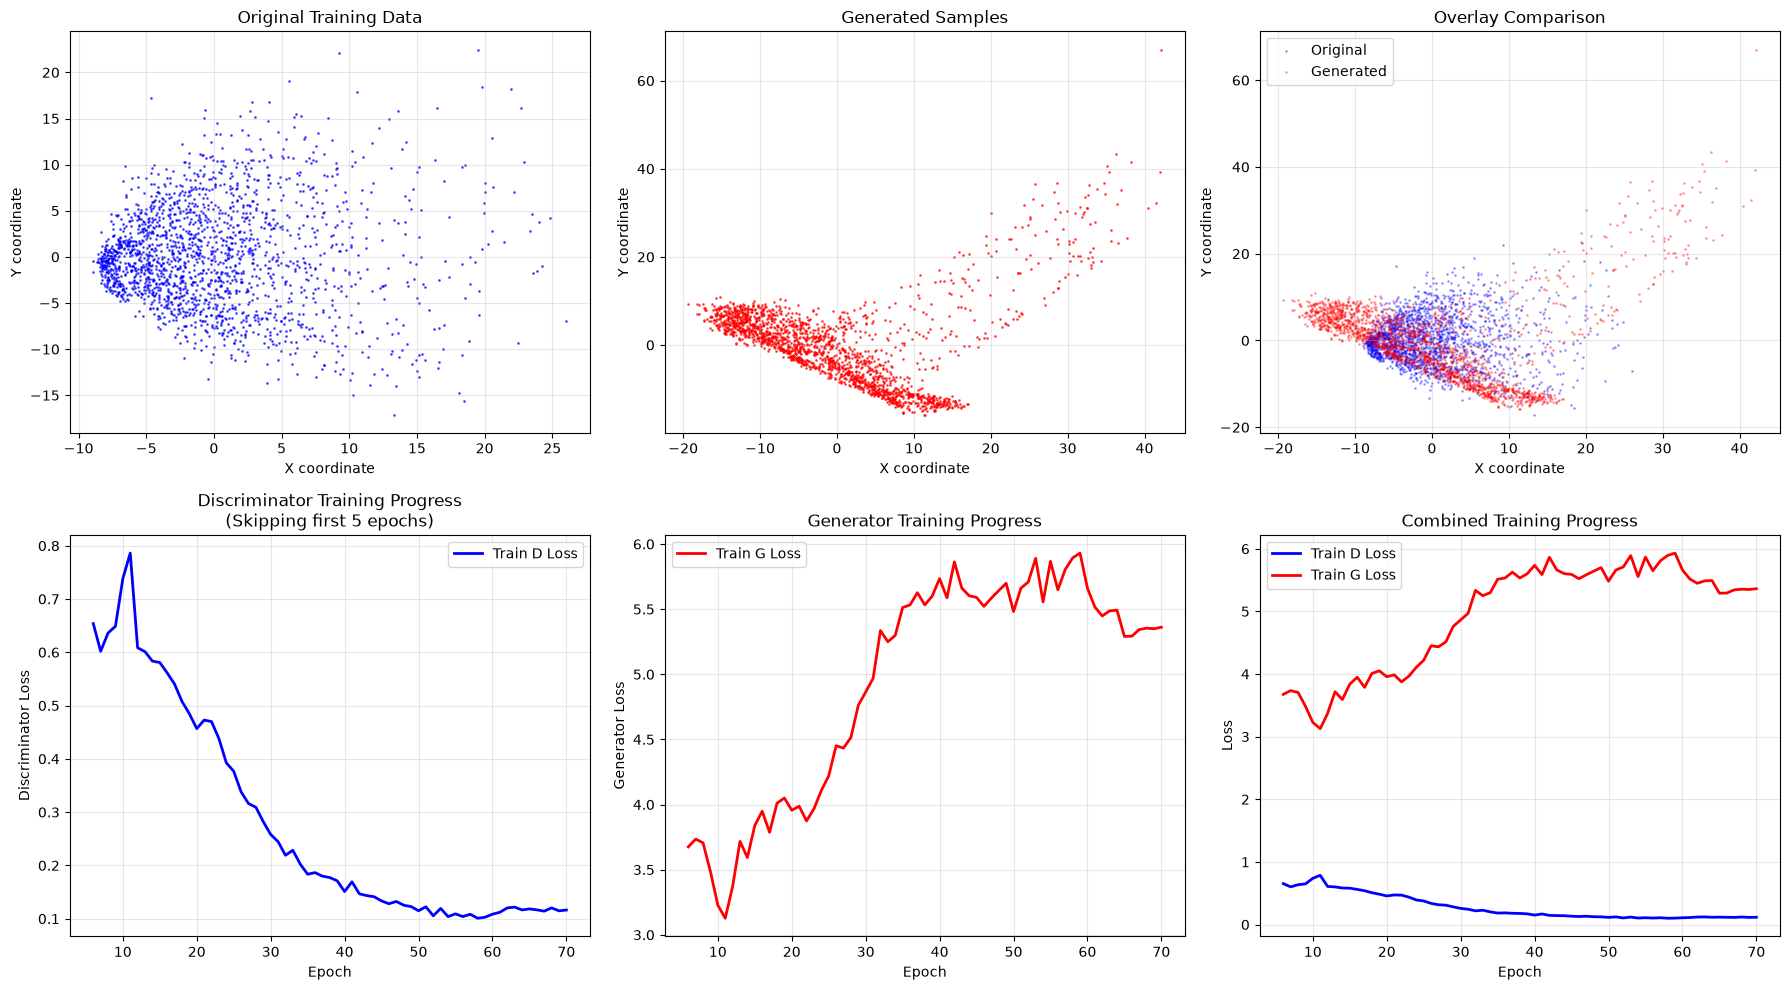

📈 Epoch 70 Summary:
   Train D Loss: 0.1163, Val D Loss: 0.1380
   Train G Loss: 5.3616, Val G Loss: 3.7005

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.129141	G_loss: 5.341227
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.032759	G_loss: 5.813052
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.166894	G_loss: 3.261414
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.131987	G_loss: 5.878996
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.057913	G_loss: 4.671265
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.131758	G_loss: 4.414636
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.094271	G_loss: 3.710623
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.191148	G_loss: 4.327605
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.053323	G_loss: 4.844161
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.090060	G_loss: 5.196499
====> Epoch: 71 Train D_loss: 0.1215, Train G_loss: 5.4042
====> Epoch: 71 Val D_loss: 0.1226, Val G_loss: 4.8839
📈 Epoch 71 Summary:
   Train D Loss: 0.1215, Val D Loss: 0.1226
   Train G Loss: 5.4042

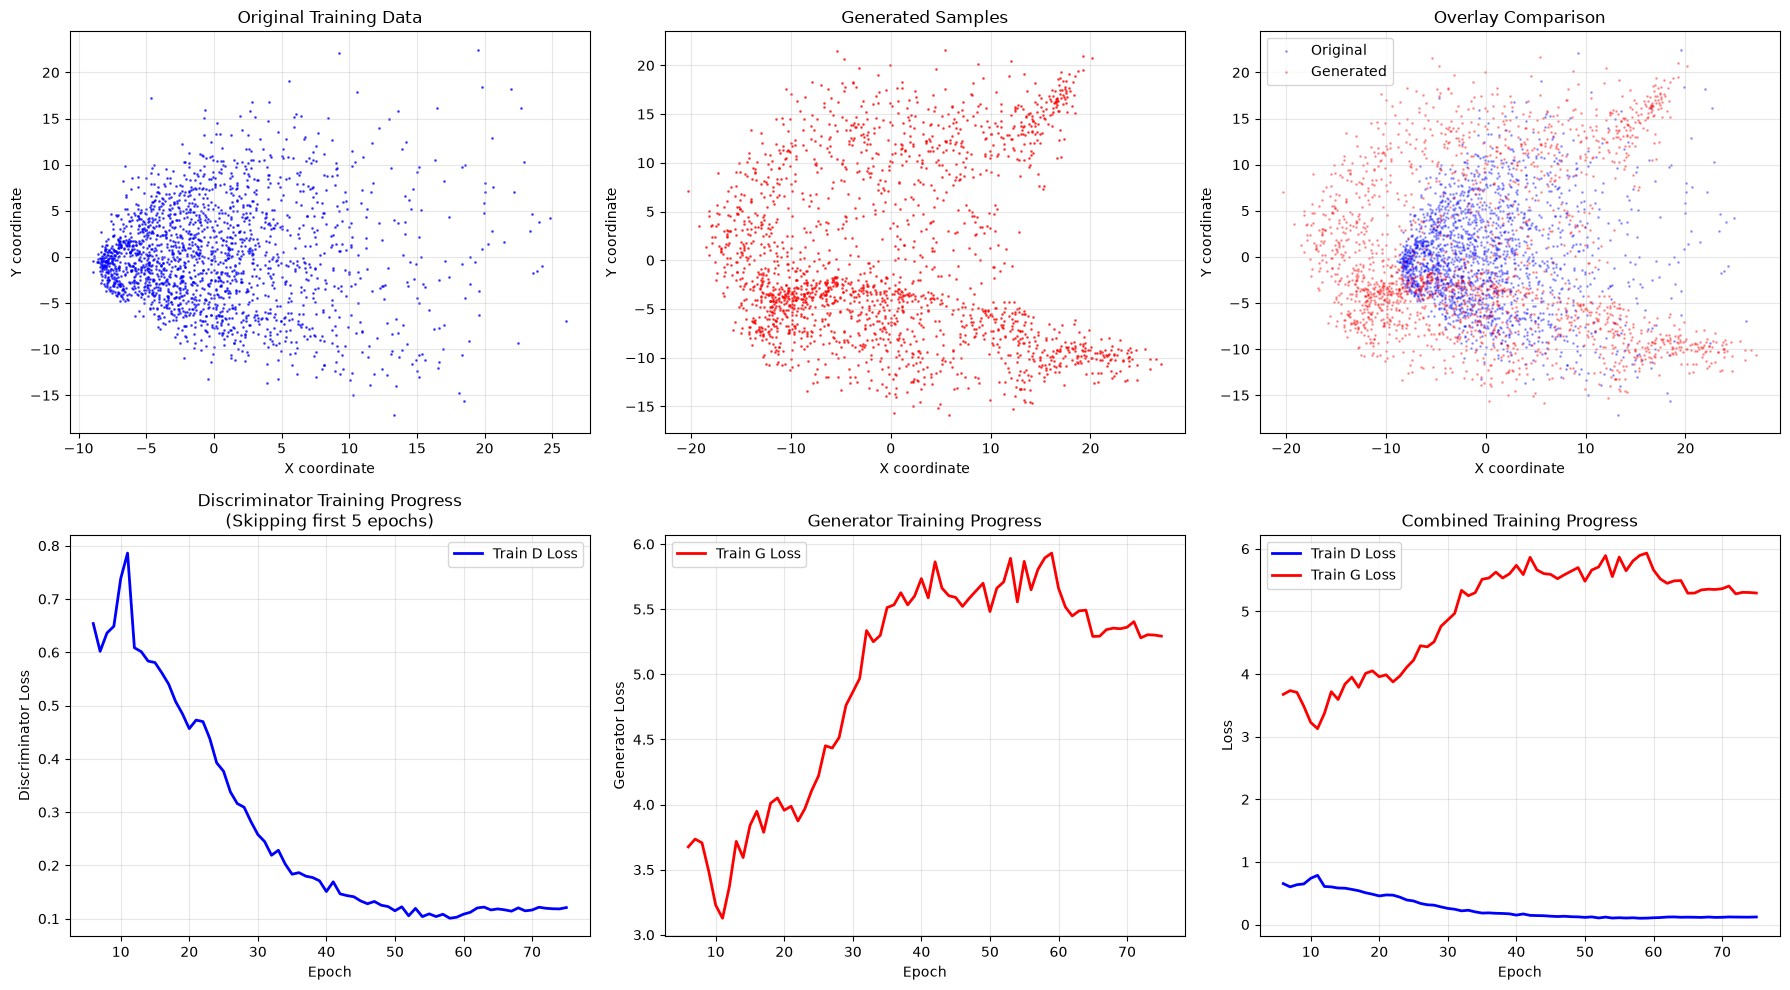

📈 Epoch 75 Summary:
   Train D Loss: 0.1209, Val D Loss: 0.1309
   Train G Loss: 5.2930, Val G Loss: 4.9530

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.151187	G_loss: 4.038418
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.050037	G_loss: 5.277930
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.170279	G_loss: 5.683087
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.059419	G_loss: 5.714482
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.085021	G_loss: 5.621781
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.142183	G_loss: 4.042267
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.152213	G_loss: 4.572165
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.105887	G_loss: 6.368468
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.052638	G_loss: 5.714691
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.103401	G_loss: 5.038065
====> Epoch: 76 Train D_loss: 0.1258, Train G_loss: 5.1971
====> Epoch: 76 Val D_loss: 0.1405, Val G_loss: 5.4187
📈 Epoch 76 Summary:
   Train D Loss: 0.1258, Val D Loss: 0.1405
   Train G Loss: 5.1971

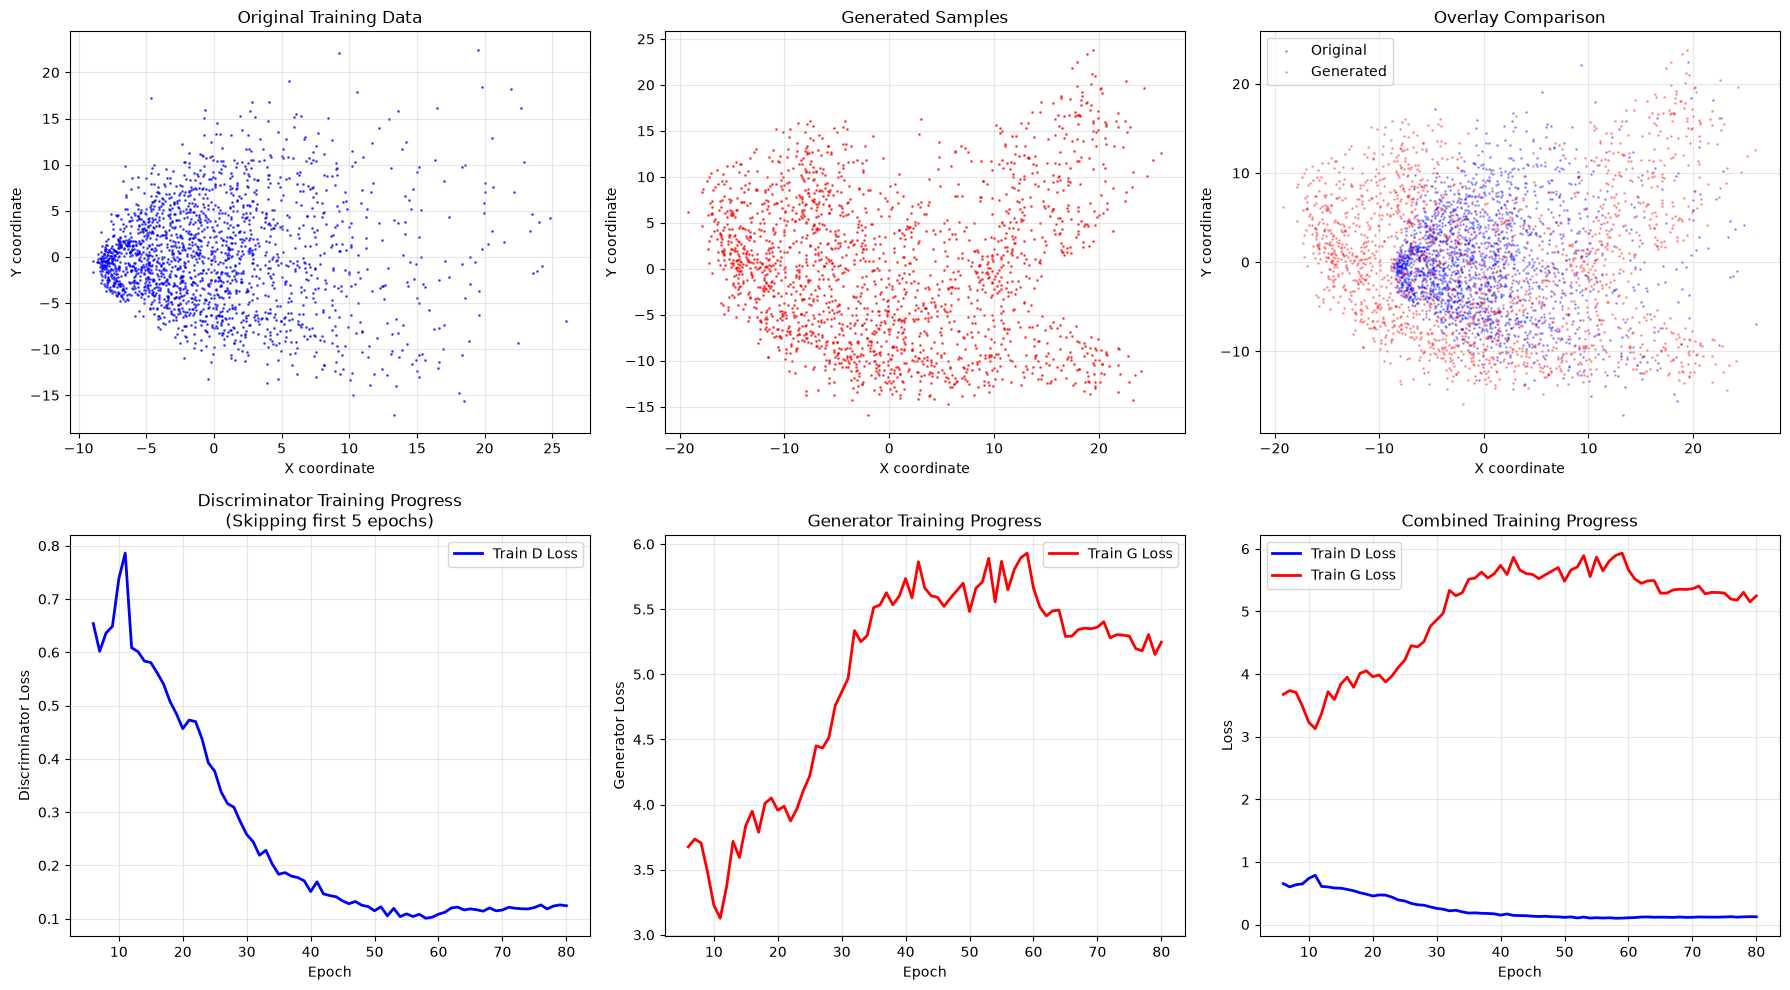

📈 Epoch 80 Summary:
   Train D Loss: 0.1243, Val D Loss: 0.1583
   Train G Loss: 5.2467, Val G Loss: 4.6567

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.148705	G_loss: 4.304493
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.121677	G_loss: 5.555900
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.099268	G_loss: 4.977698
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.118449	G_loss: 5.049798
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.081996	G_loss: 4.796206
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.032136	G_loss: 5.574141
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.112890	G_loss: 5.260424
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.238321	G_loss: 3.962708
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.172924	G_loss: 3.996084
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.119287	G_loss: 5.324507
====> Epoch: 81 Train D_loss: 0.1273, Train G_loss: 5.0697
====> Epoch: 81 Val D_loss: 0.1579, Val G_loss: 3.6795
📈 Epoch 81 Summary:
   Train D Loss: 0.1273, Val D Loss: 0.1579
   Train G Loss: 5.0697

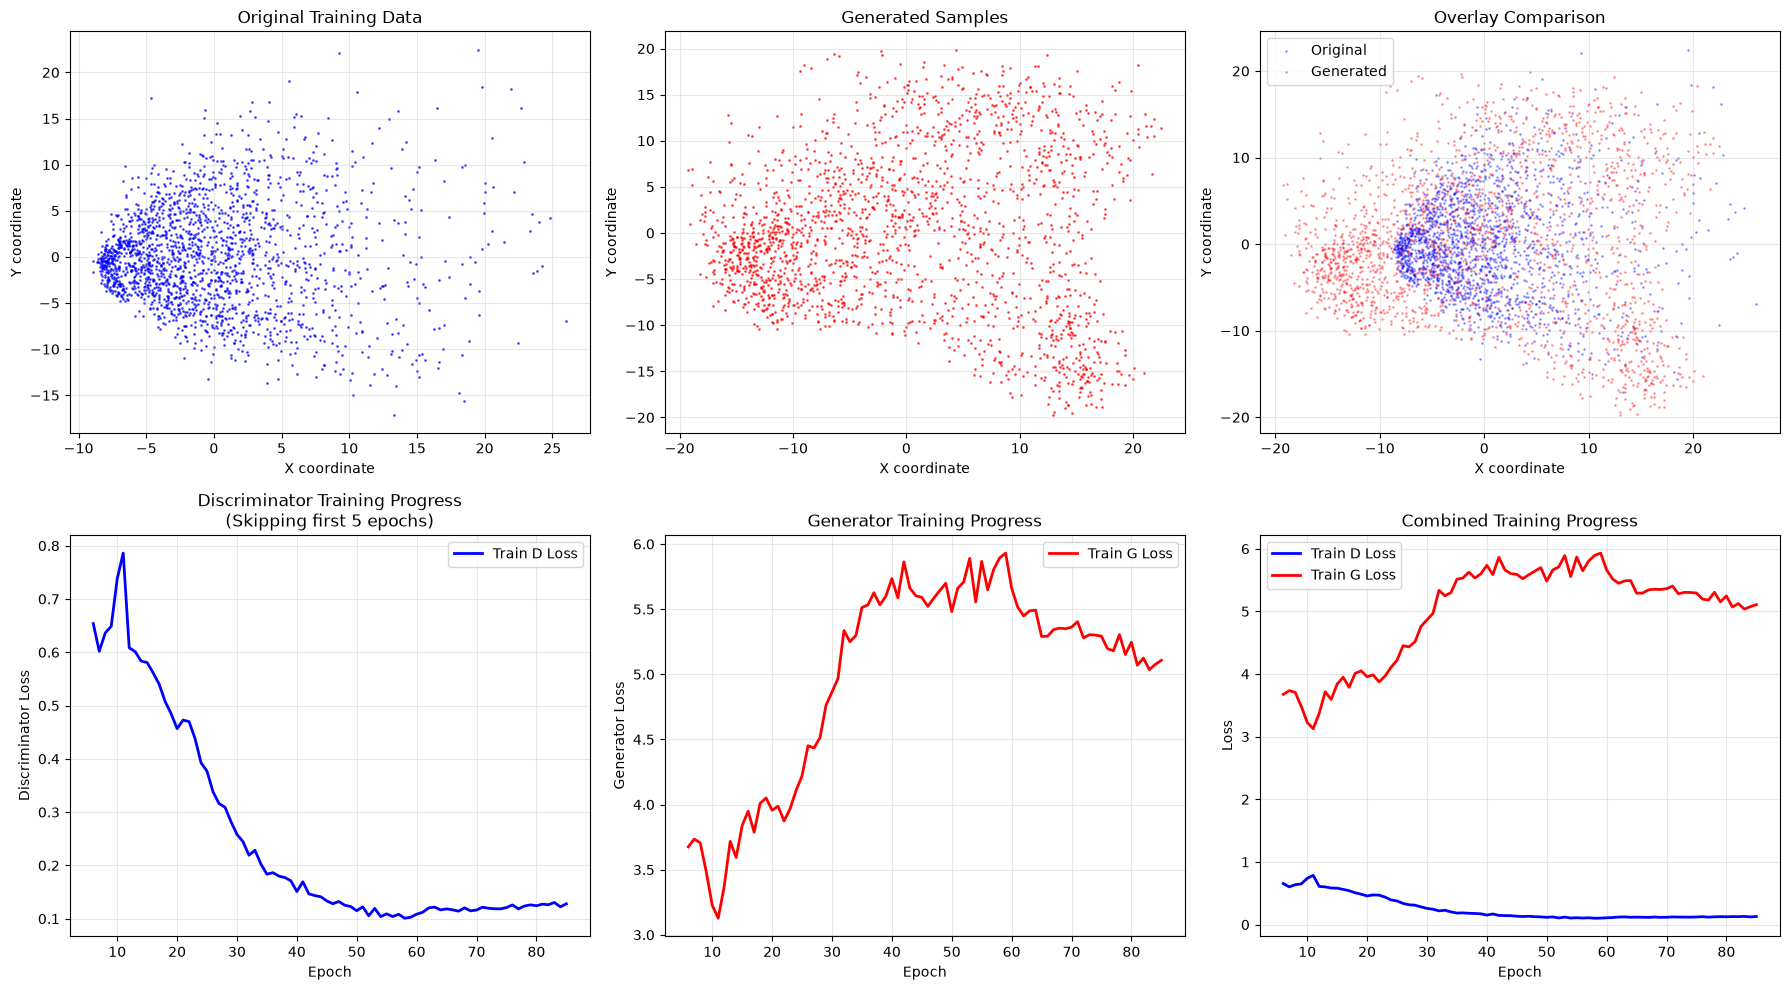

📈 Epoch 85 Summary:
   Train D Loss: 0.1279, Val D Loss: 0.1987
   Train G Loss: 5.1075, Val G Loss: 5.9924

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.297696	G_loss: 4.245529
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.081649	G_loss: 5.699749
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.114065	G_loss: 4.482338
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.152338	G_loss: 3.675961
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.111172	G_loss: 6.478102
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.145447	G_loss: 4.222187
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.180207	G_loss: 6.062451
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.114958	G_loss: 5.011453
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.083398	G_loss: 5.620737
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.048011	G_loss: 5.655763
====> Epoch: 86 Train D_loss: 0.1286, Train G_loss: 5.1688
====> Epoch: 86 Val D_loss: 0.1871, Val G_loss: 5.0782
📈 Epoch 86 Summary:
   Train D Loss: 0.1286, Val D Loss: 0.1871
   Train G Loss: 5.1688

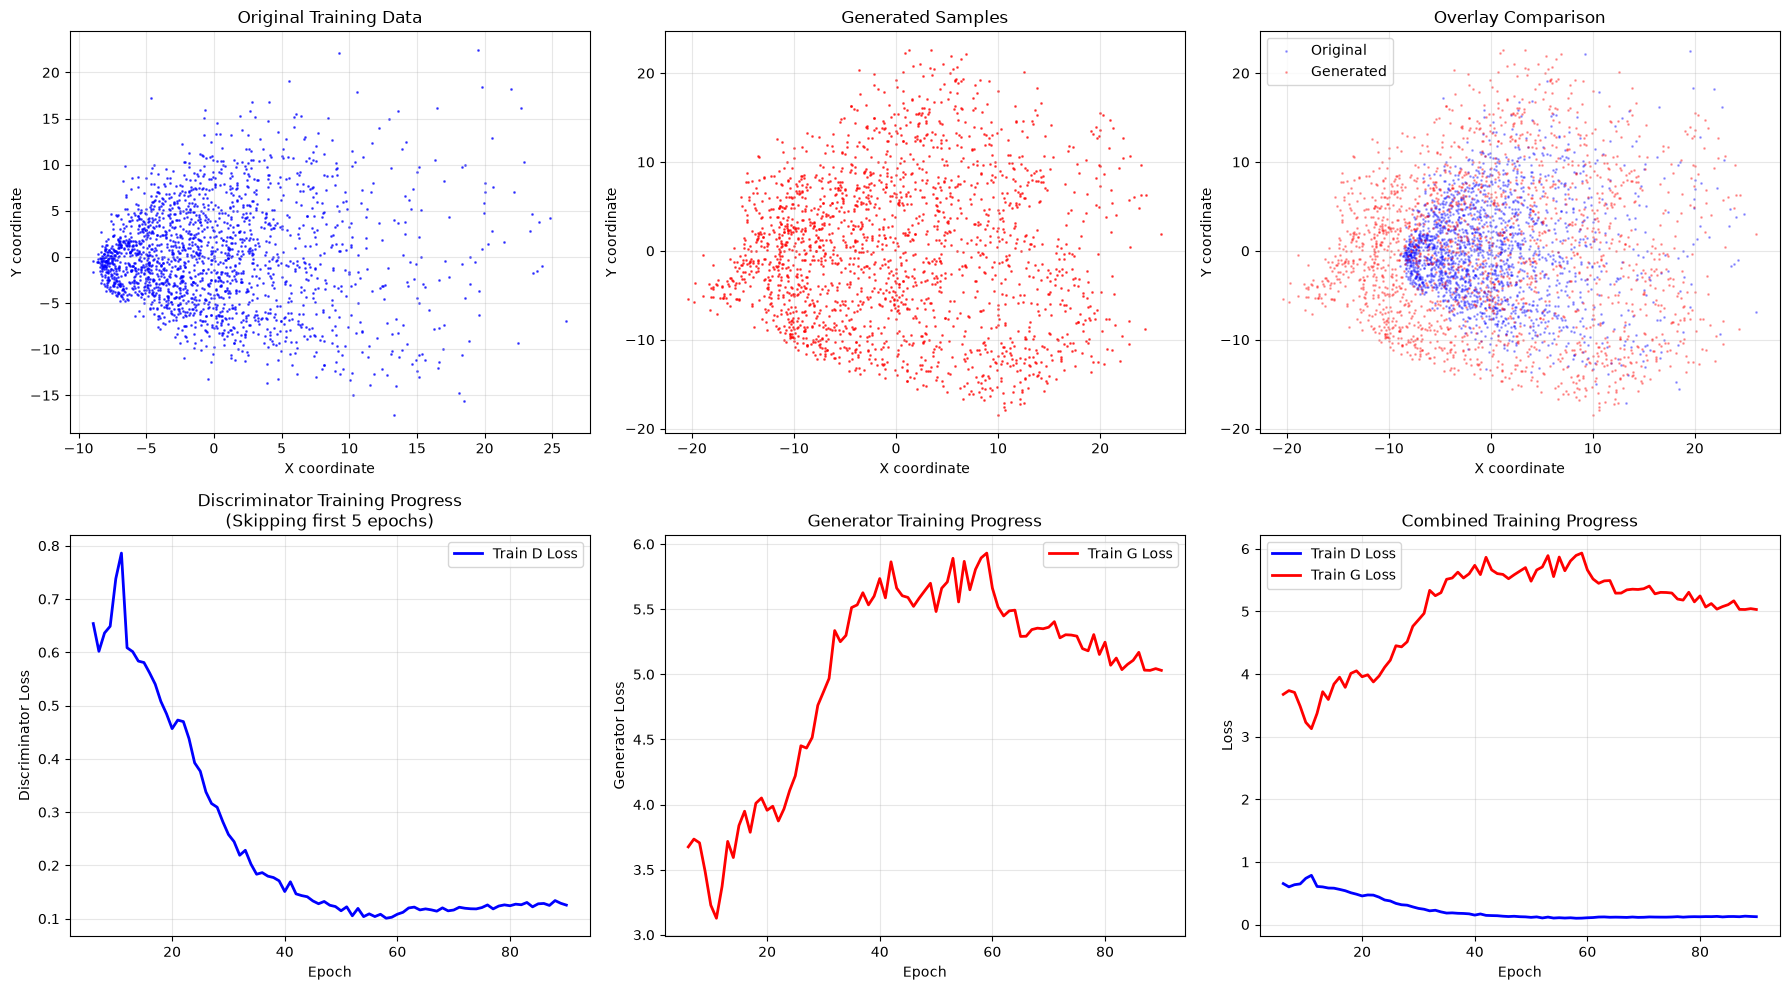

📈 Epoch 90 Summary:
   Train D Loss: 0.1255, Val D Loss: 0.1622
   Train G Loss: 5.0303, Val G Loss: 4.1918

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.163012	G_loss: 4.332705
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.089475	G_loss: 5.399032
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.067730	G_loss: 4.963081
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.077186	G_loss: 5.391109
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.306163	G_loss: 4.411173
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.087918	G_loss: 5.053500
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.159140	G_loss: 6.886522
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.105505	G_loss: 5.460884
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.155750	G_loss: 3.934347
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.154333	G_loss: 4.157523
====> Epoch: 91 Train D_loss: 0.1297, Train G_loss: 5.0933
====> Epoch: 91 Val D_loss: 0.1927, Val G_loss: 5.6377
📈 Epoch 91 Summary:
   Train D Loss: 0.1297, Val D Loss: 0.1927
   Train G Loss: 5.0933

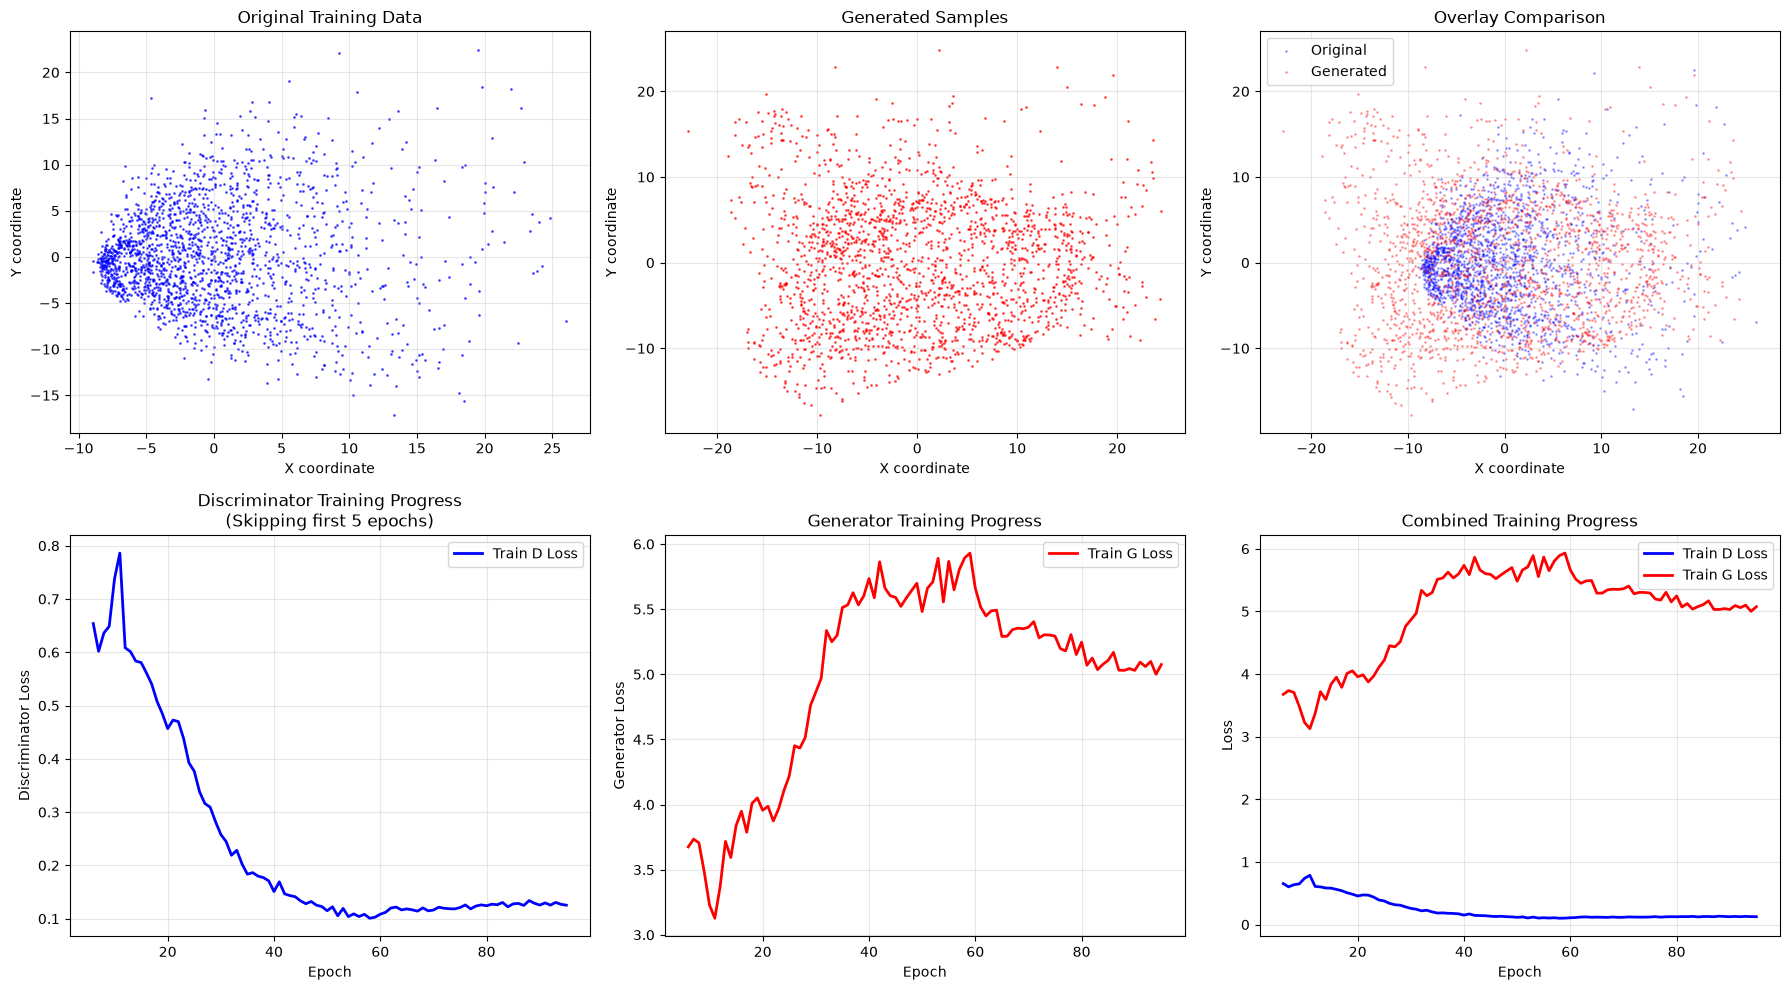

📈 Epoch 95 Summary:
   Train D Loss: 0.1254, Val D Loss: 0.1998
   Train G Loss: 5.0749, Val G Loss: 6.2444

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.105217	G_loss: 6.897748
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.093949	G_loss: 4.664146
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.070057	G_loss: 5.474645
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.127310	G_loss: 5.551812
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.118656	G_loss: 4.980716
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.115218	G_loss: 4.326423
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.136078	G_loss: 4.761458
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.094214	G_loss: 4.579125
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.282066	G_loss: 7.144897
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.111956	G_loss: 4.604581
====> Epoch: 96 Train D_loss: 0.1317, Train G_loss: 5.0689
====> Epoch: 96 Val D_loss: 0.1717, Val G_loss: 3.9168
📈 Epoch 96 Summary:
   Train D Loss: 0.1317, Val D Loss: 0.1717
   Train G Loss: 5.0689

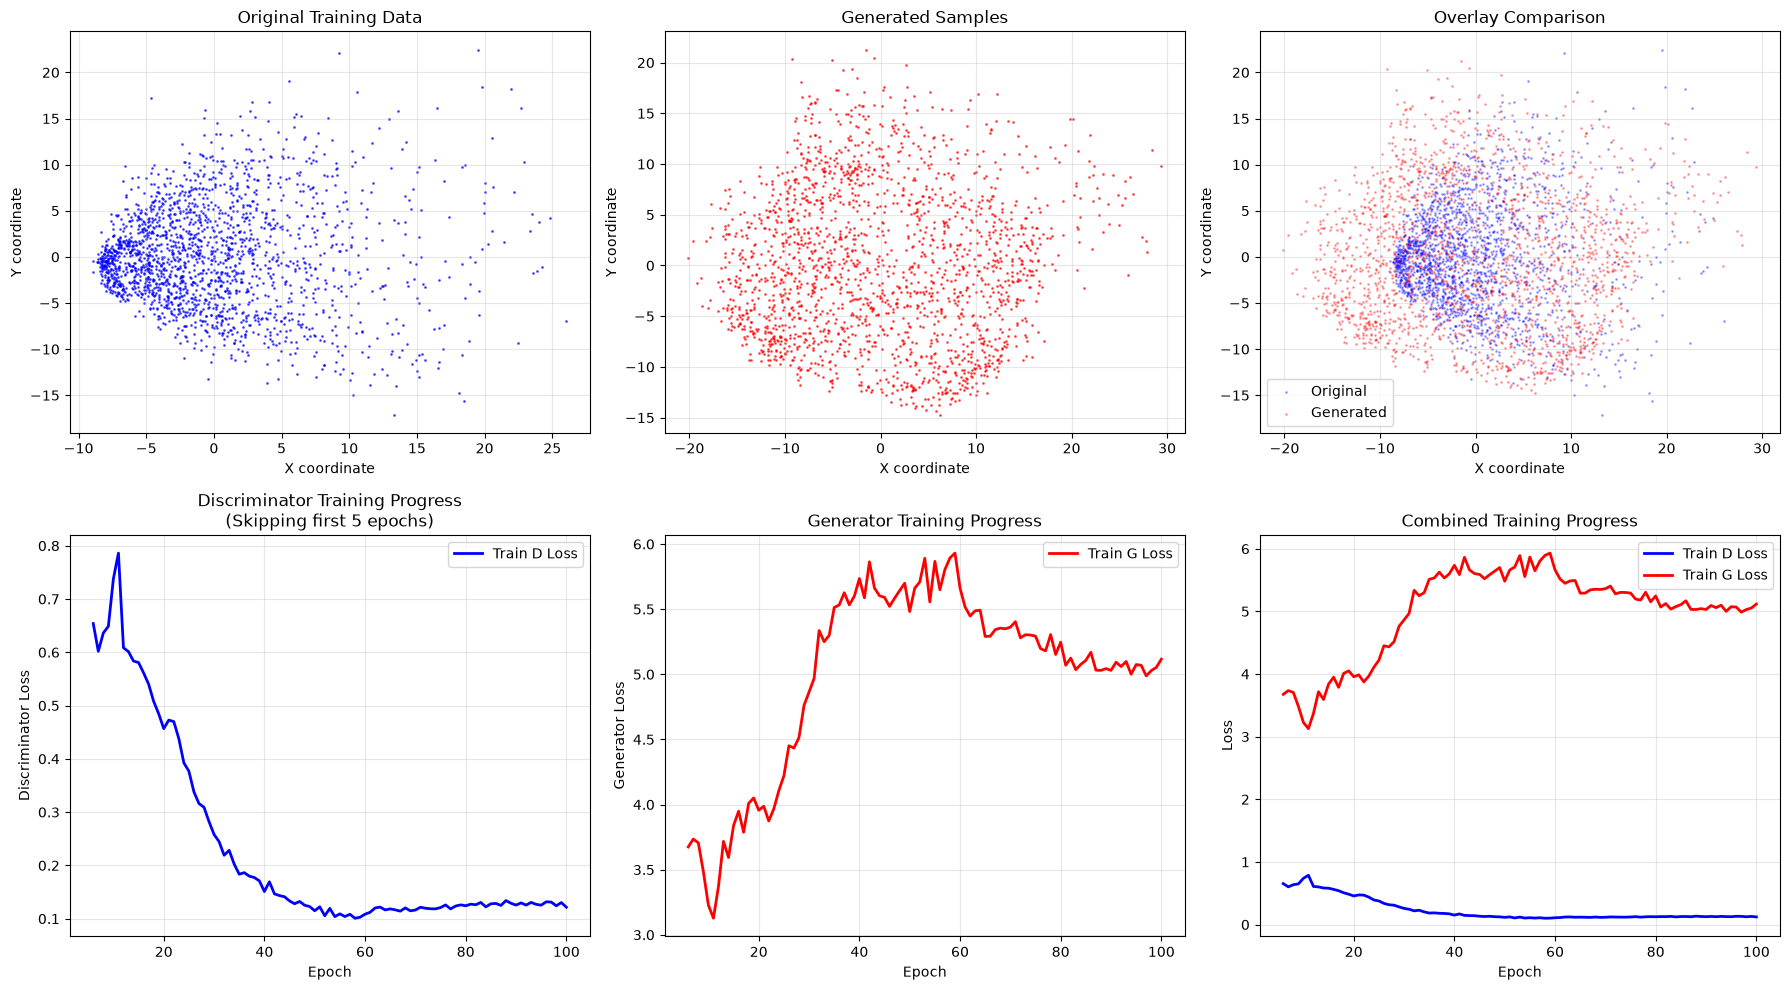

📈 Epoch 100 Summary:
   Train D Loss: 0.1215, Val D Loss: 0.1519
   Train G Loss: 5.1160, Val G Loss: 4.7899

🎉 Training completed!

🎨 Final comprehensive visualization:


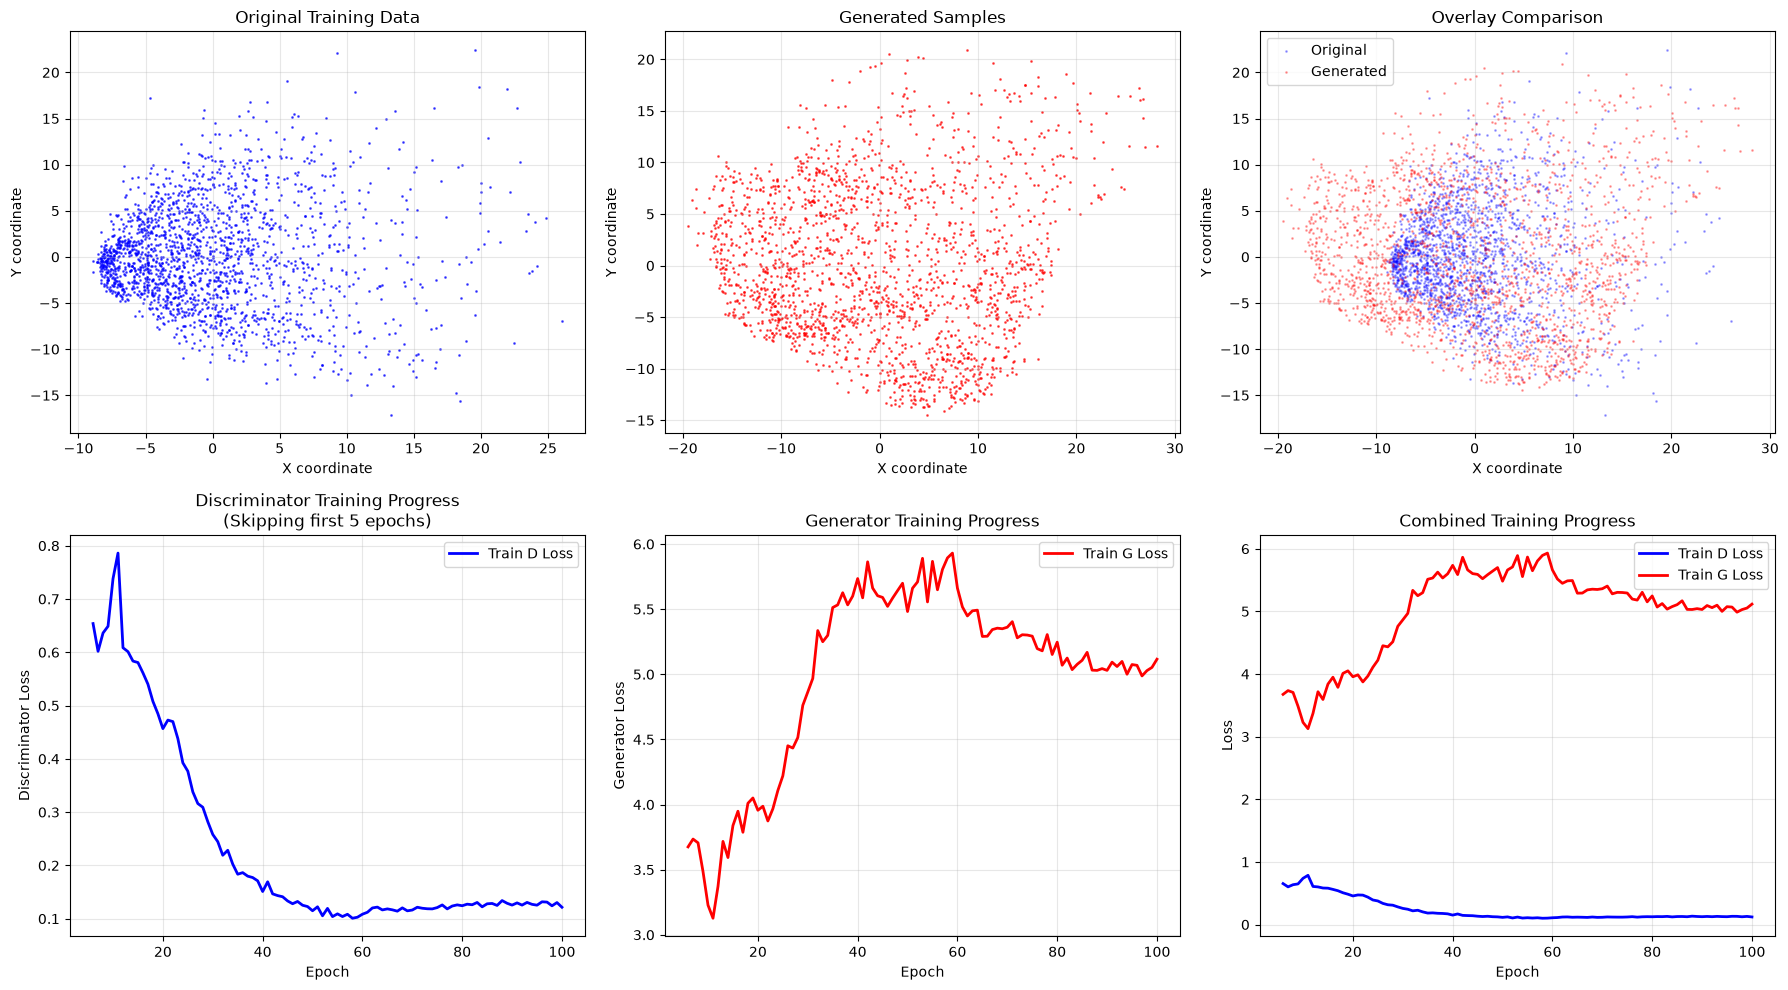

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


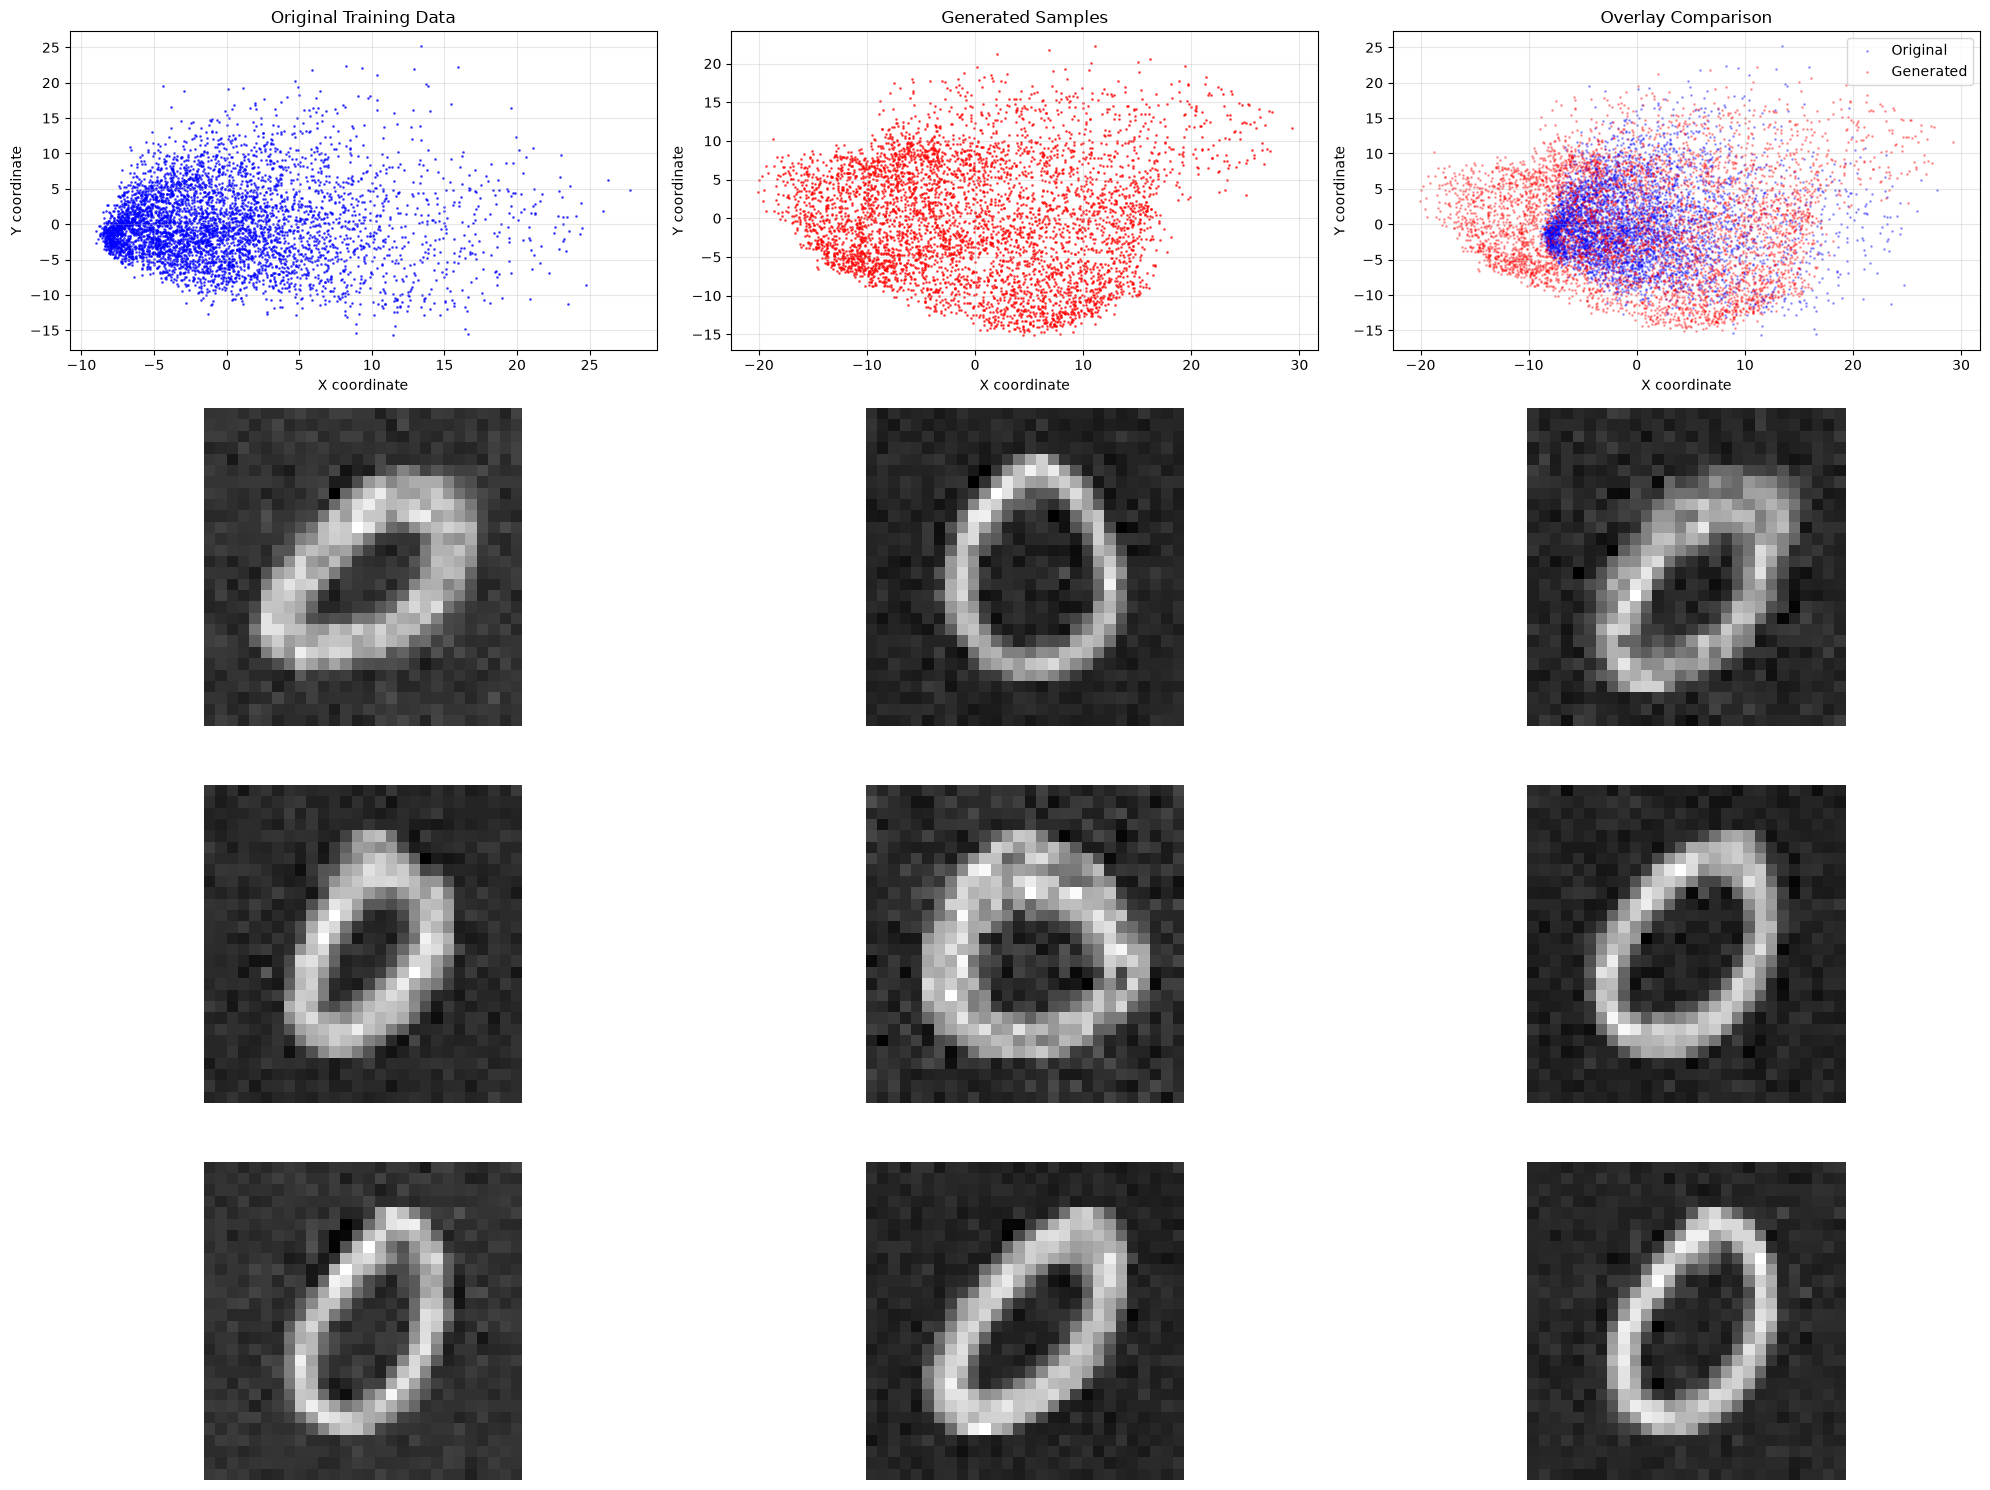

In [22]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()
